# Who are we about to lose? — Análise de retenção de colaboradores

**Group Project — Data-driven Process Improvement | NOVA FCT**  
**Versão revista: pontos 1 a 4 | Google Colab e GitHub**

<mark>🟨 **LEGENDA DE REVISÃO.** Texto com fundo amarelo e comentários `# 🟨` assinalam alterações ao ficheiro inicial ou conteúdo acrescentado. O ponto 4 é inteiramente novo. As figuras e tabelas são produzidas pelo código, e ficam incorporadas nos outputs do notebook para aparecerem no GitHub.</mark>

O conjunto de dados reúne 560 respostas anónimas de colaboradores de três organizações em Portugal. O objetivo é estudar fatores associados à intenção de procurar novo emprego e avaliar se é possível prever a classificação operacional de risco. Esta classificação **não representa saídas efetivas observadas**.

**Fontes:** `GroupProject_EN_MPbD (1).pdf` (enunciado, pp. 1–5); `Splitting_the_Data(2).pdf`; `Evaluating_Classifiers_KNN_Nayve_DecisionTree (1)(2).pdf`; `Choose_Explain_Models(2).pdf`; `Tuning_in_Machine_Learning(2).pdf`. Os resultados empíricos provêm exclusivamente de `people_operations_dataset.xlsx`.

### Execução no Google Colab

1. Abrir este `.ipynb` no Colab.
2. Escolher **Runtime → Run all**.
3. Quando solicitado na primeira célula de código, carregar `people_operations_dataset.xlsx`.
4. Guardar o notebook **com os outputs** antes de o publicar no GitHub. Os gráficos e as tabelas ficam visíveis mesmo sem executar o código no GitHub.

**Nota de privacidade:** o notebook mostra estatísticas agregadas; o Excel de respostas individuais não deve ser colocado num repositório público sem autorização para divulgar esses dados.


# **1. Problem Framing and Hypotheses**

## **1.1 O Contexto do Problema**

### **As decisões**

Perante a Sofia estão diversas decisões, a vários níveis:

- **Definição de objetivos:** existem três opções principais: prever que colaboradores têm intenção de sair; descobrir que fatores são mais preponderantes no nível de exaustão; ou segmentar os colaboradores em perfis.
- **Nível metodológico:** serão tomadas decisões relativas ao tratamento dos dados, tais como o preenchimento de *missing values*, a substituição de valores evidentemente errados (ex.: idade = 2) ou o tratamento dado a informações de foro pessoal, como idade, género ou a existência de filhos.
- **Estratégia de intervenção:** terá de ser elaborada uma estratégia ao nível das aplicações internas para colaboradores que, procurando satisfazer as necessidades dos mesmos e reduzir o *turnover*, não comprometa questões éticas nem recorra a *dark patterns*.

### **Os stakeholders**

A estratégia a adotar depende das necessidades e objetivos de diferentes stakeholders:

- **Os 3 diretores de RH**, que pretendem principalmente reduzir os custos associados ao *turnover*. Apesar de partilharem este objetivo, bem como um alinhamento comum com as práticas da Indústria 5.0, podem ter interesses competitivos distintos, e existe uma preocupação manifesta com o respeito por princípios éticos nas estratégias de retenção.
- **Os colaboradores**, que, para além de beneficiarem de uma alocação mais eficiente de recursos em programas de retenção, podem estar expostos a riscos através dos dados pessoais disponibilizados, ou devido a eventuais medidas de intervenção mais predatórias (*dark patterns*).

### **O mesmo conjunto de dados, 3 empresas**

A criação de um dataset comum apresenta benefícios, mas também limitações. Permite, por um lado, aplicar de forma mais eficaz métodos que necessitam de grandes volumes de dados, como o *machine learning*. Por outro lado, as conclusões obtidas serão mais generalistas para o mercado em estudo e não necessariamente aplicáveis a necessidades concretas de uma empresa em particular, uma vez que não existe identificador de empresa.

---

## **1.2 Framing & Hypotheses**

### **A questão central**

No problema em estudo, o principal objetivo será prever, a partir dos dados do questionário, quais os colaboradores que apresentam risco de abandonar a empresa e quais são os principais fatores que motivam este risco. Para isso, será selecionada uma variável target, e, <mark>será construído um modelo de classificação supervisionada, cuja generalização será avaliada em dados reservados para teste. O número limitado de observações (560 antes da limpeza) recomenda prudência na interpretação das métricas.</mark>

### **Target**
Ao definir qual deve ser a variável *target* a prever pelo modelo, há que considerar que as opções disponíveis (*exhaustion*, *intention to look for a new job* e *intention to quit*) representam um *pipeline* claro na evolução da vontade do colaborador em abandonar a empresa. <mark>Uma sequência conceptual possível é exaustão → procura de oportunidades → intenção de saída. Contudo, os dados são transversais e não demonstram que esta sequência temporal ou causal aconteça necessariamente.</mark>

Atuar em pontos diferentes deste *pipeline* poderá produzir efeitos distintos. Por exemplo, se um colaborador exausto for identificado, poderá ser "recaptado" antes de manifestar intenções mais "sérias" de saída. Por outro lado, a exaustão pode ser um indicador pouco robusto, uma vez que não responde diretamente ao problema "quem pretende sair".

### **Comparação dos possíveis targets**

| Target | Vantagens | Desvantagens |
|---|---|---|
| **`intention_quit`** | Mais próximo do comportamento real de saída e da pergunta dos diretores ("quem vamos perder?"). Fácil de comunicar e de transformar numa lista acionável. | <mark>Média de 3,33 na escala 1–7; uma definição binária exigiria justificar o limiar e avaliar a distribuição resultante.</mark> Sinal mais tardio: quem já decidiu sair é mais difícil de reter. |
| **`intention_lookfornewjob`** | Sinal mais precoce, portanto mais acionável (ainda há margem para intervir). <mark>Média de 2,64 (e não 2,90); é necessário analisar os vários limiares para avaliar a distribuição das classes.</mark> | Procurar emprego não implica sair (pode ser curiosidade ou negociação). Proxy mais ruidoso do *turnover* real. Provavelmente muito correlacionada com `intention_quit`. |
| **`Exhaustion`** | Distribuição mais equilibrada e mais "contínua". Muito acionável (carga de trabalho, bem-estar). Sinal ainda mais precoce no *pipeline*. | Não responde diretamente à pergunta do caso: é um estado e não uma decisão. Teoricamente é mais um *driver* (ou mediador) do que o resultado final. Escala diferente das restantes (1-5, com 5 = pior). |

**Escolha e papel das restantes variáveis:** o *target* principal será `intention_lookfornewjob`, por constituir uma variável de compromisso: suficientemente próxima da decisão de saída, mas num ponto do *pipeline* em que ainda é possível intervir. A `intention_quit` será excluída das *features* (para evitar *data leakage*, por ser quase uma reformulação do *target*). A `Exhaustion` será mantida como variável (burnout → intenção de procurar emprego). 

### **Tratamento do target como variável binária**

Para efeitos operacionais ("quem está em risco?"), o *target* será transformado numa variável binária, em que valores abaixo de um determinado limiar correspondem a "sem risco" (0) e valores iguais ou acima a "em risco" (1). Esta opção facilita a comunicação e a ação por parte dos diretores, bem como a utilização de métricas próprias de modelos de classificação (*recall*, *precision*, F1, ROC-AUC).

No entanto, esta simplificação implica perder alguma **sensibilidade** da escala ordinal original (1-7): colaboradores com respostas muito próximas, mas em lados opostos do limiar, passam a ser tratados como completamente diferentes, e a escolha do limiar é, por natureza, algo arbitrária. Este efeito será averiguado na **análise de thresholds**, na qual a coluna original (1-7) será mantida intacta e o limiar será tratado como um parâmetro, repetindo o treino e a avaliação para vários cortes (por exemplo, ≥ 3, ≥ 4 e ≥ 5) e verificando se o desempenho e os principais *drivers* se mantêm estáveis.

### **Hipóteses a Testar**

| ID | Hipótese | Variáveis a testar | Relação esperada |
|---|---|---|---|
| H1 | **Clima organizacional:** Uma perceção mais positiva do clima organizacional (confiança, comunicação, justiça e camaradagem) está associada a uma menor intenção de procurar um novo emprego. | `ca_camaraderie`, <mark>`ca_leadersCredibility`</mark>, <mark>`ca_leaderCommunication`</mark>, <mark>`ca_Personal_Development`</mark>, <mark>`ca_justice`</mark>, <mark>`ca_work_family`</mark> | Negativa |
| H2 | **Características do trabalho:** Características profissionais mais favoráveis (variedade de competências, identidade e significado das tarefas, autonomia e feedback) estão associadas a uma menor intenção de procurar um novo emprego. | `Skill_Variety`, `Task_Identity`, `Task_Significance`, `Autonomy`, `Feedback` | Negativa |
| H3 | **Exaustão:** Níveis mais elevados de exaustão dos colaboradores estão associados a uma maior intenção de procurar um novo emprego. | `Exhaustion` | Positiva |
| H4 | **Desenvolvimento profissional:** Uma menor perceção de oportunidades de desenvolvimento pessoal e progressão na carreira está associada a uma maior intenção de procurar um novo emprego. | <mark>`ca_Personal_Development`</mark>, `n_progressions`, `years_in_position` | Negativa* |
| H5 | **Antiguidade:** A antiguidade na empresa e na função está associada à intenção de procurar um novo emprego, podendo existir uma relação não linear. | `years_in_company`, `years_in_position` | Não linear** |
| H6 | **Formação e progressão:** Colaboradores com mais formação e progressões na carreira tendem a apresentar uma menor intenção de procurar um novo emprego. | `training` (3 variáveis), `n_progressions` | Negativa |
| H7 | **Fatores sociodemográficos:** A intenção de procurar um novo emprego apresenta diferenças entre grupos sociodemográficos, nomeadamente em função da idade e do género. | `age`, `is_female` | Exploratória*** |

**Notas sobre as relações esperadas:**

- *H4: Espera-se uma relação negativa entre a perceção de oportunidades de desenvolvimento e a intenção de procurar emprego.
- **H5: Não se assume uma relação linear. Uma maior antiguidade poderá estar associada a uma menor intenção de saída, devido à integração e estabilidade profissional. Contudo, poderá também existir um aumento da intenção de saída em situações de estagnação profissional.
- ***H7: Não se define antecipadamente uma direção para a relação. Diferenças entre grupos etários ou de género serão investigadas empiricamente, sem assumir que determinado grupo apresenta necessariamente maior intenção de saída.


<mark>🟨 **CONTROLO DO ENQUADRAMENTO:** o *Exhibit 2* do enunciado indica as médias originais `intention_lookfornewjob = 2,64`, `intention_quit = 3,33` e `Exhaustion = 2,90`. A escolha de `intention_lookfornewjob` mantém-se pela lógica de intervenção precoce, não por ter uma média superior a `intention_quit`.</mark>

# **2. Data quality and cleaning**

O enunciado exige quantificar os dados em falta e os valores implausíveis, executar uma estratégia e justificar as perdas de informação. Mantemos em separado (i) as regras determinísticas de correção e (ii) a imputação estatística, que será ajustada apenas no treino durante o ponto 4.

<mark>🟨 **ALTERADO:** o carregamento passa a funcionar em Colab através de upload, no VS Code quando o Excel está ao lado do notebook e neste ambiente de análise. Este código evita caminhos absolutos pessoais que não funcionariam no GitHub.</mark>

In [1]:
# 🟨 NOVO — revisto e documentado
from pathlib import Path
import warnings
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

sns.set_theme(style="whitegrid", font_scale=0.93)
pd.set_option("display.max_columns", 60)
plt.rcParams["figure.dpi"] = 115

ficheiro = Path("people_operations_dataset.xlsx")
if not ficheiro.exists():
    candidato = Path("reference_data/people_operations_dataset.xlsx")
    if candidato.exists():
        ficheiro = candidato
    else:
        try:
            from google.colab import files
        except ImportError as erro:
            raise FileNotFoundError(
                "Coloca people_operations_dataset.xlsx na pasta do notebook."
            ) from erro
        print("Seleciona o ficheiro people_operations_dataset.xlsx:")
        carregados = files.upload()
        if "people_operations_dataset.xlsx" not in carregados:
            raise FileNotFoundError("O Excel esperado não foi carregado.")

df = pd.read_excel(ficheiro, sheet_name="dataframe")
print("Dataset original:", df.shape)
print("Nomes de colunas:")
display(pd.DataFrame({"variavel": df.columns, "tipo": df.dtypes.astype(str).values}))
display(df.head(5))

assert df.shape == (560, 28), "Verifica se carregaste o Excel correto."


Dataset original: (560, 28)
Nomes de colunas:


,variavel,tipo
0,indice,int64
1,age,float64
2,is_office,int64
3,is_female,int64
4,has_children,int64
5,marital status,float64
6,n_children,float64
7,position_in_Company,float64
8,years_in_position,float64
9,years_in_company,float64


,indice,age,is_office,is_female,has_children,marital status,n_children,position_in_Company,years_in_position,years_in_company,n_training_lastyear,n_training_job,n_training_personalDevelopment,n_progressions,Skill_Variety,Task_Identity,Task Significance,Autonomy,Feedback,ca_camaraderie,ca_leadersCredibility,ca_leaderCommunication,ca_Personal_Development,ca_justice,ca_work_family,Exhaustion,intention_lookfornewjob,intention_quit
0,0,51.0,1,0,1,4.0,1.0,5.0,4.0,24.0,3.0,1.0,1.0,6.0,7.0,5.0,6.0,7.0,5.0,4.5,4.0,4.0,4.0,4.0,4.0,2.5,1,1
1,1,50.0,1,1,0,0.0,0.0,4.0,25.0,25.0,3.0,3.0,3.0,0.0,NaN,5.0,6.0,6.0,5.0,4.0,4.0,4.0,4.0,4.0,4.0,2.0,2,3
2,2,23.0,1,1,0,0.0,0.0,4.0,0.3,0.3,5.0,5.0,4.0,0.0,1.0,5.0,5.0,3.0,NaN,4.0,4.0,NaN,3.5,5.0,4.0,2.0,7,1
3,3,37.0,1,0,1,3.0,2.0,4.0,1.0,0.8,1.0,1.0,1.0,1.0,7.0,7.0,5.0,6.0,6.0,3.5,4.0,3.0,4.0,3.0,3.0,2.5,1,2
4,4,34.0,1,1,1,4.0,3.0,3.0,4.0,0.3,0.0,0.0,0.0,0.0,5.0,7.0,7.0,5.0,4.0,2.5,3.0,NaN,2.0,3.0,3.0,4.5,5,6


Linhas com ≥ 1 valor em falta: 449/560 (80.2%)
Total de células em falta: 841
Percentagem global em falta: 5.36 %


,n_missing,pct_missing
variavel,,
ca_leaderCommunication,67,11.96
ca_Personal_Development,61,10.89
ca_work_family,59,10.54
Skill_Variety,54,9.64
ca_camaraderie,53,9.46
ca_leadersCredibility,53,9.46
n_training_job,49,8.75
Task Significance,44,7.86
n_training_lastyear,42,7.50


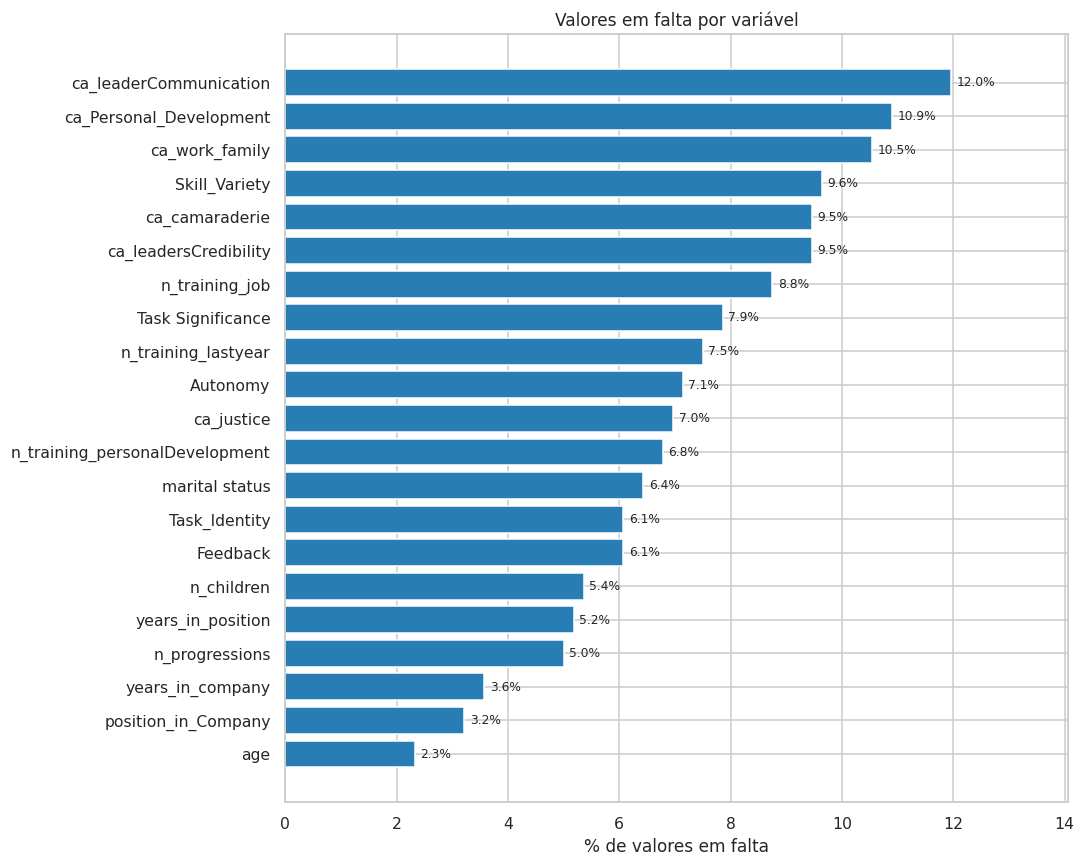

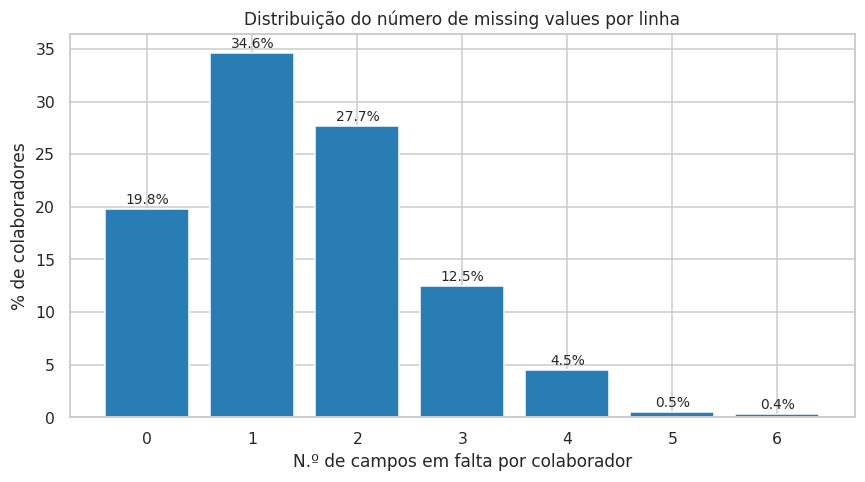

In [2]:
# 🟨 ALTERADO — revisto e documentado
# Diagnóstico dos valores em falta — tabela e dois gráficos
missing = pd.DataFrame({
    "n_missing": df.isna().sum(),
    "pct_missing": df.isna().mean() * 100,
}).sort_values("pct_missing", ascending=False)

rows_with_na = int(df.isna().any(axis=1).sum())
na_per_row = df.isna().sum(axis=1).value_counts().sort_index()

print(f"Linhas com ≥ 1 valor em falta: {rows_with_na}/{len(df)} "
      f"({rows_with_na / len(df) * 100:.1f}%)")
print("Total de células em falta:", int(df.isna().sum().sum()))
print("Percentagem global em falta:", round(df.isna().mean().mean() * 100, 2), "%")
display(missing.round(2).rename_axis("variavel"))

fig, ax = plt.subplots(figsize=(10, 8))
plot_missing = missing.loc[missing.pct_missing.gt(0)].sort_values("pct_missing")
ax.barh(plot_missing.index, plot_missing["pct_missing"], color="#287db5")
for i, valor in enumerate(plot_missing["pct_missing"]):
    ax.text(valor + 0.1, i, f"{valor:.1f}%", va="center", fontsize=8)
ax.set_xlim(0, plot_missing.pct_missing.max() + 2.1)
ax.set_xlabel("% de valores em falta")
ax.set_title("Valores em falta por variável")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(8, 4.5))
pct_rows = na_per_row / len(df) * 100
bars = ax.bar(na_per_row.index.astype(str), pct_rows.values, color="#287db5")
for bar, valor in zip(bars, pct_rows.values):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
            f"{valor:.1f}%", ha="center", fontsize=9)
ax.set_xlabel("N.º de campos em falta por colaborador")
ax.set_ylabel("% de colaboradores")
ax.set_title("Distribuição do número de missing values por linha")
plt.tight_layout()
plt.show()


,n_missing,media,mediana,desvio_padrao,assimetria,min,max,|media-mediana|/desvio
n_progressions,28,1.01,0.0,1.79,8.56,0.0,30.0,0.56
n_training_job,49,1.76,1.0,2.88,7.38,0.0,44.0,0.26
n_training_personalDevelopment,38,1.62,1.0,2.55,3.65,0.0,21.0,0.24
n_training_lastyear,42,2.24,2.0,2.63,2.54,0.0,20.0,0.09
years_in_position,29,6.24,4.0,5.84,1.45,0.0,35.0,0.38
years_in_company,20,9.75,10.0,7.18,1.06,0.1,43.0,0.03
ca_Personal_Development,61,3.55,4.0,0.78,-0.79,1.0,5.0,0.58
n_children,30,1.00,1.0,0.93,0.60,0.0,5.0,0.00
ca_camaraderie,53,3.15,3.5,1.13,-0.59,1.0,5.0,0.31
ca_leadersCredibility,53,3.15,3.0,1.20,-0.48,1.0,5.0,0.12


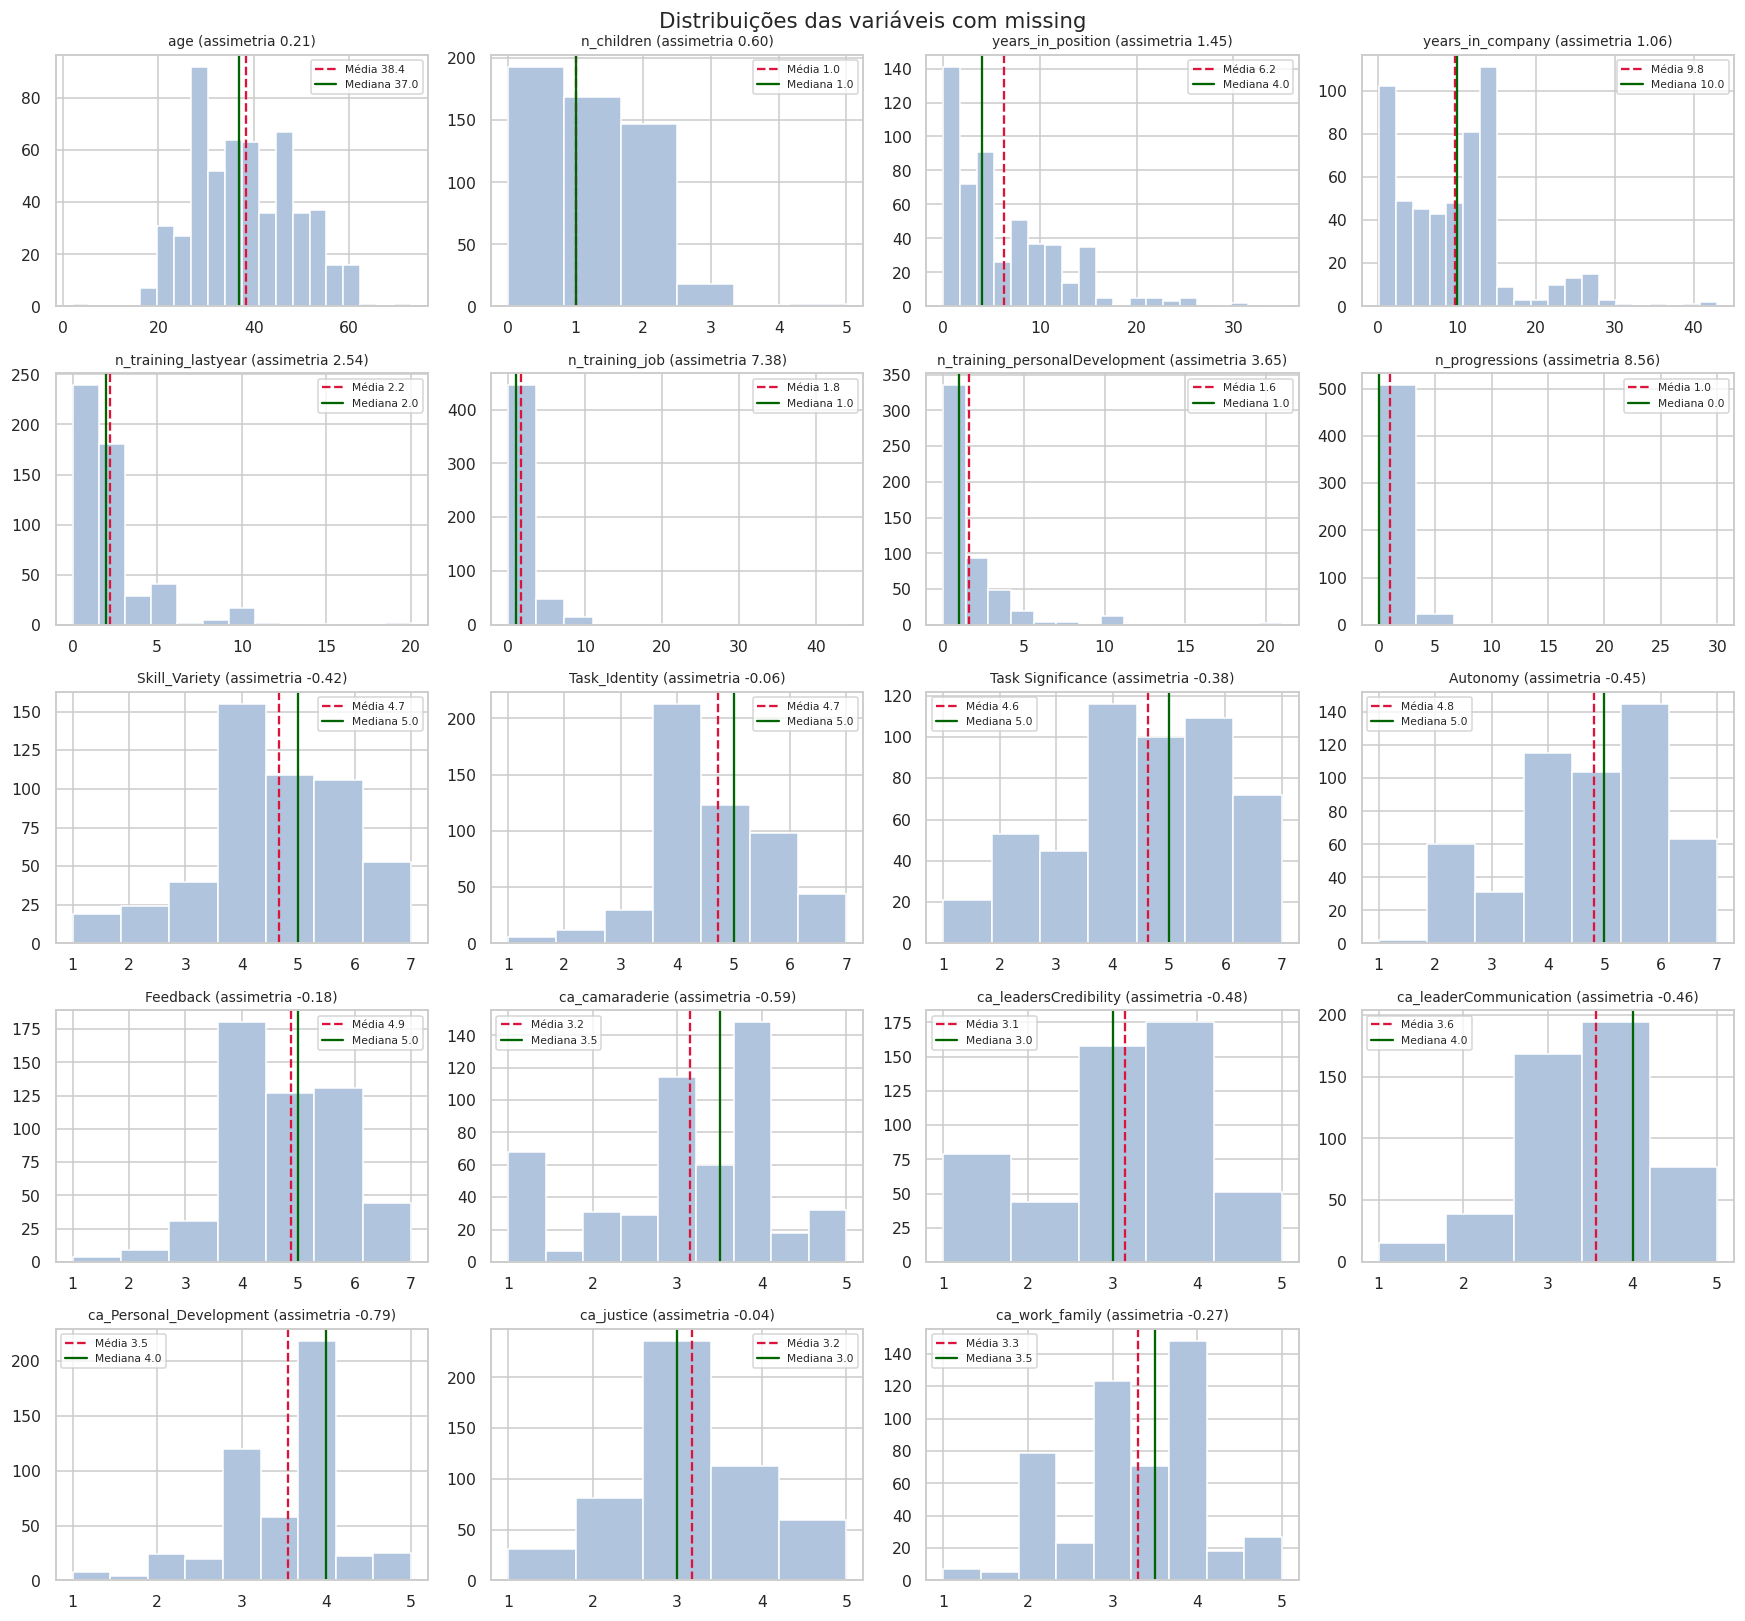

In [3]:
# 🟨 ALTERADO — revisto e documentado
# Comparação média–mediana nas variáveis numéricas com valores em falta
cat_cols = ["marital status", "position_in_Company"]
num_cols = [c for c in df.columns if df[c].isna().any() and c not in cat_cols]

summary = pd.DataFrame({
    "n_missing": df[num_cols].isna().sum(),
    "media": df[num_cols].mean(),
    "mediana": df[num_cols].median(),
    "desvio_padrao": df[num_cols].std(),
    "assimetria": df[num_cols].skew(),
    "min": df[num_cols].min(),
    "max": df[num_cols].max(),
})
summary["|media-mediana|/desvio"] = (
    (summary["media"] - summary["mediana"]).abs() / summary["desvio_padrao"]
)
display(summary.sort_values("assimetria", key=abs, ascending=False).round(2))

n_cols_grid = 4
n_rows_grid = math.ceil(len(num_cols) / n_cols_grid)
fig, axes = plt.subplots(n_rows_grid, n_cols_grid, figsize=(16, 3.0*n_rows_grid))
axes = np.asarray(axes).flatten()
for ax, col in zip(axes, num_cols):
    vals = df[col].dropna()
    ax.hist(vals, bins=min(20, vals.nunique()), color="lightsteelblue", edgecolor="white")
    ax.axvline(vals.mean(), color="crimson", ls="--", label=f"Média {vals.mean():.1f}")
    ax.axvline(vals.median(), color="darkgreen", label=f"Mediana {vals.median():.1f}")
    ax.set_title(f"{col} (assimetria {vals.skew():.2f})", fontsize=9)
    ax.legend(fontsize=7)
for ax in axes[len(num_cols):]:
    ax.axis("off")
fig.suptitle("Distribuições das variáveis com missing", fontsize=14)
plt.tight_layout()
plt.show()


## **2.1 Identificação e Tratamento de Missing Values**

O primeiro passo na preparação de dados corresponde à identificação dos *missing values* no dataset. Para isso, elaborou-se o gráfico de barras que mostra, por ordem decrescente, as variáveis com maior percentagem de *missing values*.

Através do mesmo, conclui-se que as variáveis com maior percentagem de *missing values* são "Leader Communication", "Personal Development" e "Work Family", com mais de 10% dos valores em falta.

<mark>🟨 ALTERADO — A figura correspondente é agora gerada e guardada diretamente no output da célula Python.</mark>
É interessante notar também que cerca de 75% das linhas têm entre 1 e 3 colunas sem valores, e que cerca de 20% do total não tem qualquer *missing value*. Assim, a estratégia mais adequada para tratar os *missing values* não será a eliminação (uma vez que isso implicaria eliminar 80% das linhas), mas sim a imputação.

<mark>🟨 ALTERADO — A figura correspondente é agora gerada e guardada diretamente no output da célula Python.</mark>
### **Estratégia de imputação**

Dado que nenhuma variável tem mais de 12% de valores em falta, é aceitável recorrer a uma imputação simples, através de medidas de tendência central. Uma vez que a grande maioria das variáveis foi medida em escalas discretas ou corresponde a contagens com distribuição assimétrica, a média seria pouco adequada: nas escalas, pode produzir valores que não existem na escala de resposta e, nas contagens, é influenciada por poucos casos extremos. Recorrer-se-á, por isso, à **mediana**, que é também mais robusta a valores atípicos.

Exceção feita às variáveis "Estado Civil" (`marital status`) e "Posição na Empresa" (`position_in_Company`) que, por estarem associadas a códigos categóricos, serão imputadas com recurso à **moda**.

<mark>🟨 ALTERADO — A figura correspondente é agora gerada e guardada diretamente no output da célula Python.</mark>
### **Perda de informação**

A imputação pela mediana (ou moda) atribui o mesmo valor a todos os casos em falta de uma variável, o que implica perda de informação. Por um lado, concentra os valores no centro da distribuição, reduzindo a variabilidade e enfraquecendo ligeiramente as correlações entre variáveis e com o *target*, o que pode levar a subestimar algumas associações testadas nas hipóteses. Por outro, ignora a relação com as restantes respostas do colaborador (por exemplo, o seu valor nos outros itens de clima) e <mark>não permite corrigir eventuais padrões de ausência de resposta não aleatória:</mark> se os colaboradores que não respondem forem sistematicamente diferentes (por exemplo, mais desligados da empresa), a imputação não recupera esse sinal e pode introduzir enviesamento. No caso da moda, a categoria mais frequente é ainda reforçada.

Estes efeitos são atenuados pela baixa proporção de valores em falta (cerca de 5% das células e no máximo 12% por variável). Na fase de modelação, a imputação será ajustada apenas nos dados de treino, para evitar fuga de informação para o teste.



<mark>🟨 **ALTERADO — Distinção metodológica:** a imputação global feita abaixo destina-se apenas à análise exploratória (ponto 3). Para o modelo supervisionado (ponto 4), os parâmetros de imputação serão calculados dentro do Pipeline em cada conjunto de treino, evitando *data leakage*.</mark>

Posição > antiguidade na empresa: 15
Colaboradores com antiguidade incompatível com entrada aos 16 anos:
Valores das colunas binárias:
is_office {0: 242, 1: 317, 3: 1}
is_female {0: 311, 1: 248, 5: 1}
has_children {0: 206, 1: 354}
Identificadores duplicados: [5, 5]
Observação suspeita e ocorrência com o mesmo identificador:


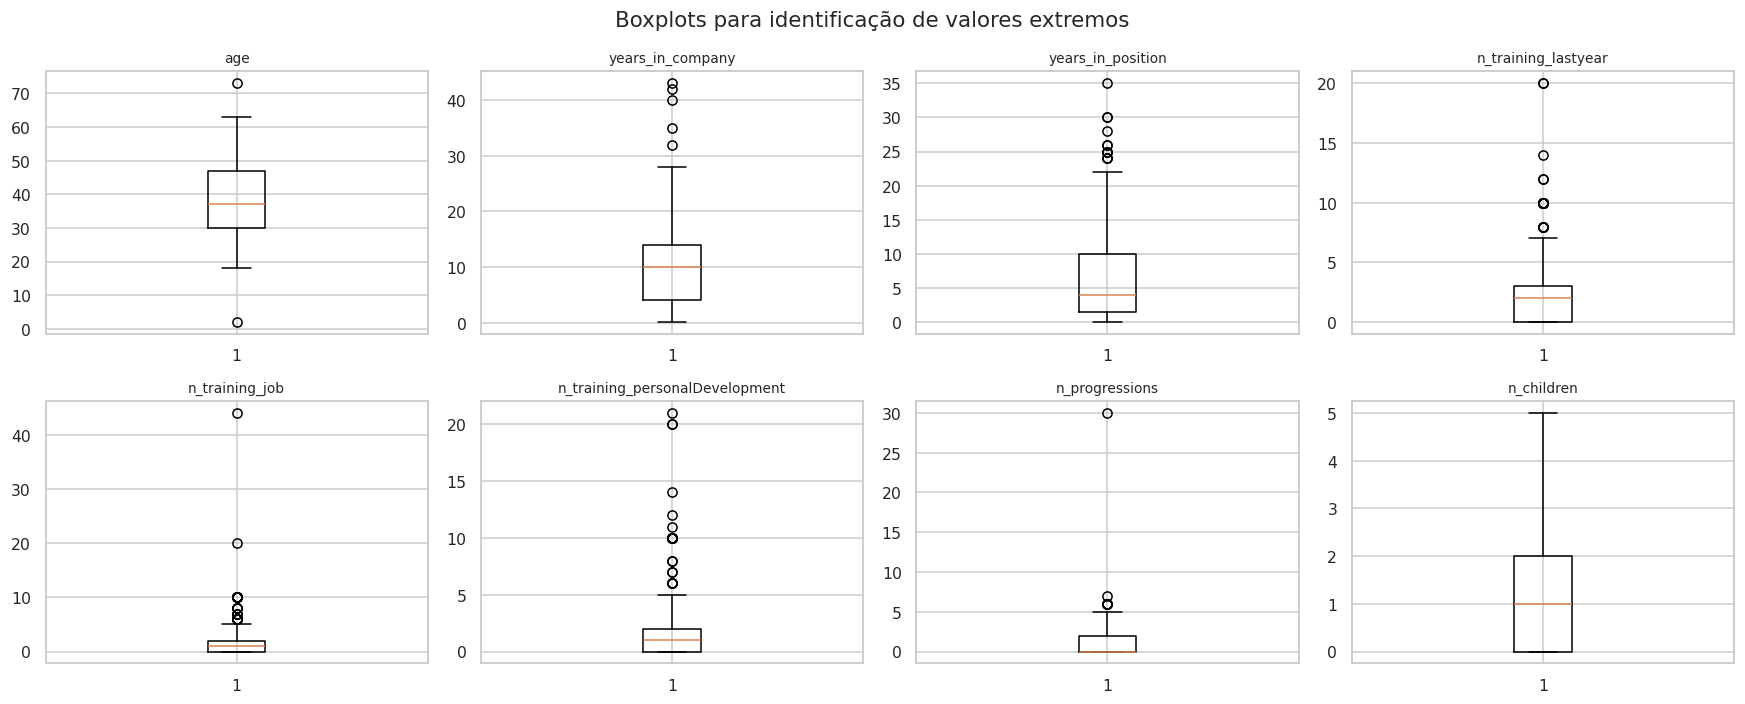

,indice,age,years_in_company,years_in_position
16,5,2.0,0.4,0.4
196,196,57.0,42.0,30.0
292,292,22.0,7.0,7.0


,min,max
Skill_Variety,1.0,7.0
Task_Identity,1.0,7.0
Task Significance,1.0,7.0
Autonomy,1.0,7.0
Feedback,1.0,7.0
ca_camaraderie,1.0,5.0
ca_leadersCredibility,1.0,5.0
ca_leaderCommunication,1.0,5.0
ca_Personal_Development,1.0,5.0
ca_justice,1.0,5.0


,5,16
indice,5.0,5.0
age,48.0,2.0
is_office,1.0,3.0
is_female,0.0,5.0
has_children,1.0,1.0
marital status,4.0,1.0
n_children,1.0,5.0
position_in_Company,3.0,3.0
years_in_position,4.0,0.4
years_in_company,27.0,0.4


In [4]:
# 🟨 ALTERADO — revisto e documentado
# Deteção de valores extremos e violação de regras lógicas
cols_box = ["age", "years_in_company", "years_in_position",
            "n_training_lastyear", "n_training_job",
            "n_training_personalDevelopment", "n_progressions", "n_children"]

fig, axes = plt.subplots(2, 4, figsize=(16, 6.5))
for ax, col in zip(axes.flatten(), cols_box):
    ax.boxplot(df[col].dropna())
    ax.set_title(col, fontsize=9)
fig.suptitle("Boxplots para identificação de valores extremos", fontsize=14)
plt.tight_layout()
plt.show()

print("Posição > antiguidade na empresa:",
      int((df["years_in_position"] > df["years_in_company"]).sum()))

print("Colaboradores com antiguidade incompatível com entrada aos 16 anos:")
display(df.loc[df["years_in_company"] > df["age"] - 16,
               ["indice", "age", "years_in_company", "years_in_position"]])

print("Valores das colunas binárias:")
for col in ["is_office", "is_female", "has_children"]:
    print(col, df[col].value_counts(dropna=False).sort_index().to_dict())

print("Identificadores duplicados:",
      df.loc[df["indice"].duplicated(keep=False), "indice"].tolist())

likert = ["Skill_Variety", "Task_Identity", "Task Significance",
          "Autonomy", "Feedback", "ca_camaraderie", "ca_leadersCredibility",
          "ca_leaderCommunication", "ca_Personal_Development",
          "ca_justice", "ca_work_family"]
display(df[likert].agg(["min", "max"]).T)

print("Observação suspeita e ocorrência com o mesmo identificador:")
display(df.loc[[5, 16]].T)


## **2.2 Identificação e Tratamento de Outliers**

A próxima etapa no tratamento de dados consiste na indetificação de outliers. Aqui, tomou-se como outliers não apenas os valores que diferem substancialmente da tendência do conjunto mas principalmente valores irrealista ou impossíveis. Este tratamento visa sobretudo parâmetros que expressam anos, como a Idade, ou mesmo inconsistências entre duas variáveis como número de anos na empresa e número de anos na mesma posição.

### **As variáveis potencialmente problemáticas**
**Idade**: Na idade, foram detetados exatamente dois outliers, colaborador com 2 anos e um com 73 anos. Relativamente ao último, uma vez que tem a sua função classificada como 5, <mark>a legenda identifica a categoria 5 como posição de liderança; apesar disso, a função não comprova a idade. O valor 73 não é impossível por si só e foi mantido, sem evidência suficiente para o declarar erro.</mark>
Por outro lado, o colaborador identificado com idade = 2 apresenta diversos registos "estranhos" em diferentes parâmetros. Primeiramente, apresenta um índice incorreto e ainda valor 3 na variável binária "in_office" tal como acontece na variável binária "is_female" onde o valor é 5. Uma pesquisa generalizada no dataset para valores incorretos nestas variáveis binárias revelou que este foi o único registo onde tal se verificou.
Dadas estas imprecisões, opta-se por remover a linha 18 do ficheiro excel, de modo a reduzir o ruído do dataset. 

**Years_in_company/years_in_position**: Nestas variáveis, procurou-se encontrar imprecisões em que o tempo de permanência numa posição é superior ao tempo de permanência na empresa, algo ilógico, tal como situações em que o tempo na empresa, quando subtraído à idade do colaborador conduz a valores pouco coerentes. Neste âmbito, utilizou-se como threshold o valor mínimo legal para exercer uma profissão em Portugal, que é de 16 anos.
Foram identificadas 15 ocorrências de colaboradores, em que os anos na posição superam os anos na empresa, tendo-se optado por igualar ambos os parâmetros ao menor valor de entre ambos (Por exemplo se a variável "years_in_position" tiver um valor de 21 atribuído, e a variável "years_in_company" apenas de 10, a primeira variável será igualada a este último valor).
Com o limiar de 16 anos, foram identificados 2 casos em que a antiguidade na empresa não é compatível com o limiar de 16 anos. Contudo, uma vez que a idade estimada de entrada na empresa, destes dois casos, é de 15 anos, opta-se pela não remoção dos dados.

**N_training / n_progressions**: nestas variáveis de contagem, a distribuição é fortemente assimétrica, com a maioria dos valores entre 0 e 10. Optou-se por não eliminar linhas, uma vez que isso implicaria perder informação das restantes variáveis para corrigir um único campo. Foram tratados como valores implausíveis, passando a *missing* e sendo posteriormente imputados pela mediana, apenas dois casos: `n_progressions = 30` (30 progressões em 14 anos de empresa, quando o valor seguinte mais alto é 7) e `n_training_job = 44` (mais do dobro do segundo maior valor e incoerente com as restantes variáveis de formação do mesmo colaborador). Os restantes valores elevados (por exemplo, 10 e 20 formações) foram mantidos por serem plausíveis, e repetem-se com frequência, o que sugere estimativas arredondadas.

**N_children**: nesta variável, 30 registos têm valor em falta. Em 13 deles, a variável `has_children` indica que o colaborador não tem filhos, pelo que o valor em falta foi preenchido com 0, por dedução lógica e não por imputação estatística. Nos restantes 17 casos (`has_children = 1`), aplicou-se a imputação pela mediana, que resulta em 1 e é coerente com a existência de filhos.

<mark>🟨 ALTERADO — A figura correspondente é agora gerada e guardada diretamente no output da célula Python.</mark>

<mark>🟨 **ALTERADO — Auditabilidade:** a remoção da observação problemática é feita por uma condição verificável sobre idade e códigos binários inválidos. É preservado um DataFrame anterior à imputação para permitir o treino correto no ponto 4.</mark>

In [5]:
# 🟨 ALTERADO — revisto e documentado
# Limpeza determinística, reutilizável no ponto 4
def aplicar_regras_sem_imputar(dados):
    dados = dados.copy()

    # 🟨 ALTERADO: detetar a linha corrompida por critérios e não por posição fixa
    mask_corrompida = (
        dados["age"].lt(16) &
        (~dados["is_office"].isin([0, 1])) &
        (~dados["is_female"].isin([0, 1]))
    )
    print("Linhas claramente corrompidas:", dados.index[mask_corrompida].tolist())
    dados = dados.loc[~mask_corrompida].copy()

    mask_anos = dados["years_in_position"] > dados["years_in_company"]
    dados.loc[mask_anos, "years_in_position"] = dados.loc[mask_anos, "years_in_company"]

    dados.loc[dados["n_progressions"] > 20, "n_progressions"] = np.nan
    dados.loc[dados["n_training_job"] > 40, "n_training_job"] = np.nan

    mask_filhos = dados["has_children"].eq(0) & dados["n_children"].isna()
    dados.loc[mask_filhos, "n_children"] = 0
    return dados


df_sem_imputacao = aplicar_regras_sem_imputar(df)
assert len(df_sem_imputacao) == 559
assert not (df_sem_imputacao["years_in_position"] >
            df_sem_imputacao["years_in_company"]).any()

# 🟨 ALTERADO: imputação GLOBAL usada apenas nos testes exploratórios
df_clean = df_sem_imputacao.copy()
med_emp = df_clean["years_in_company"].median()
med_pos = df_clean["years_in_position"].median()
df_clean["years_in_company"] = df_clean["years_in_company"].fillna(
    np.maximum(med_emp, df_clean["years_in_position"].fillna(0)))
df_clean["years_in_position"] = df_clean["years_in_position"].fillna(
    np.minimum(med_pos, df_clean["years_in_company"]))

cat_cols = ["marital status", "position_in_Company"]
num_cols = [c for c in df_clean if df_clean[c].isna().any() and c not in cat_cols]
for col in num_cols:
    df_clean[col] = df_clean[col].fillna(df_clean[col].median())
for col in cat_cols:
    df_clean[col] = df_clean[col].fillna(df_clean[col].mode()[0])

verificacao = pd.DataFrame({
    "Verificação": ["Linhas mantidas", "Missing finais",
                    "Violações de antiguidade", "Duplicados de índice"],
    "Valor": [len(df_clean), int(df_clean.isna().sum().sum()),
              int((df_clean["years_in_position"] >
                   df_clean["years_in_company"]).sum()),
              int(df_clean["indice"].duplicated().sum())]
})
display(verificacao)
assert df_clean.isna().sum().sum() == 0


Linhas claramente corrompidas: [16]


,Verificação,Valor
0,Linhas mantidas,559
1,Missing finais,0
2,Violações de antiguidade,0
3,Duplicados de índice,0


# **3. Exploratory Data Analysis and Hypothesis Testing**

A análise exploratória procura determinar quais as hipóteses iniciais que encontram suporte nos dados e descobrir relações inesperadas. As medidas são associativas e não demonstram relações de causa e efeito. Para esta fase utiliza-se o `df_clean`, preservando-se em separado o `df_sem_imputacao` para o modelo supervisionado.

<mark>🟨 **ALTERADO:** distinguimos explicitamente exploração estatística (conjunto completo) e validação preditiva (treino/teste). Todas as tabelas e figuras seguintes são outputs executados do notebook, visíveis no GitHub.</mark>

,count,mean,median,min,max
intention_lookfornewjob,559.0,2.637,2.0,1.0,7.0
intention_quit,559.0,3.326,4.0,1.0,7.0
Exhaustion,559.0,2.895,3.0,1.0,5.0


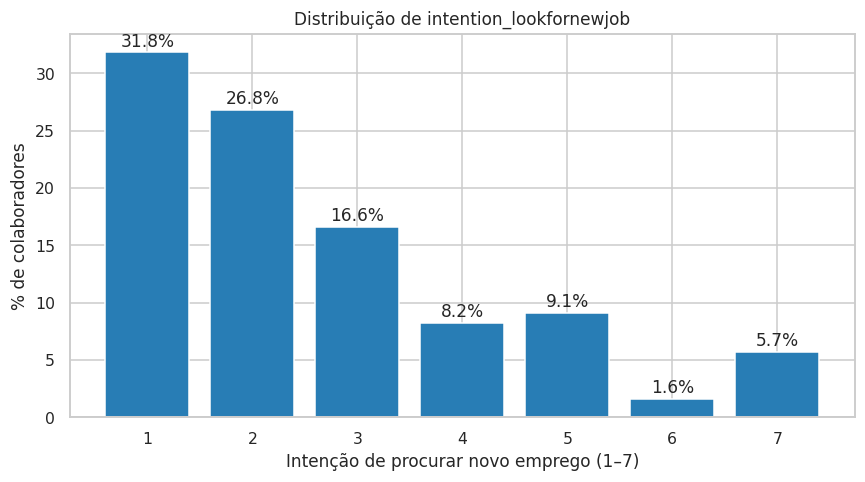

,pct_intention_quit_ge_5
intention_lookfornewjob,
1,9.0
2,8.7
3,30.1
4,34.8
5,68.6
6,77.8
7,75.0


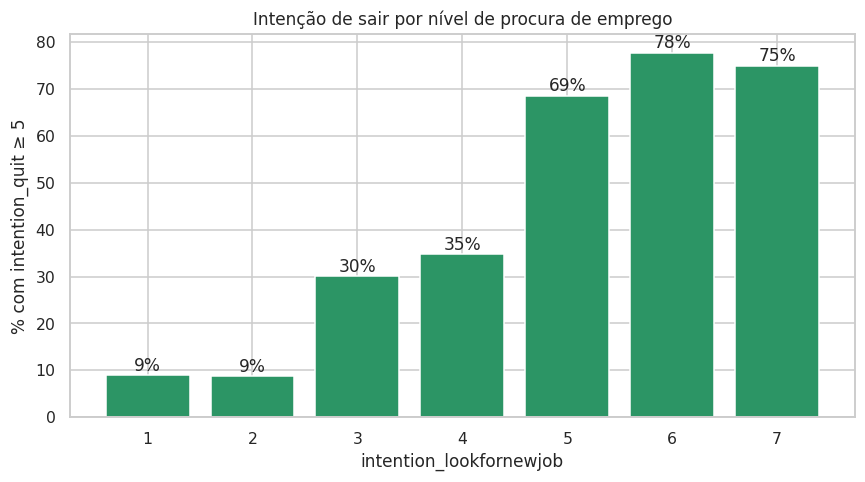

In [6]:
# 🟨 ALTERADO — revisto e documentado
# Distribuição dos dois targets e da exaustão — confirmação das médias
target = "intention_lookfornewjob"
quit_col = "intention_quit"

medias_target = df_clean[[target, quit_col, "Exhaustion"]].agg(
    ["count", "mean", "median", "min", "max"]
).T
display(medias_target.round(3))

dist = df_clean[target].value_counts().sort_index()
pct = dist / len(df_clean) * 100
fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.bar(dist.index.astype(str), pct.values, color="#287db5")
for bar, valor in zip(bars, pct.values):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height()+0.5,
            f"{valor:.1f}%", ha="center")
ax.set_xlabel("Intenção de procurar novo emprego (1–7)")
ax.set_ylabel("% de colaboradores")
ax.set_title("Distribuição de intention_lookfornewjob")
plt.tight_layout()
plt.show()

share = df_clean.groupby(target)[quit_col].apply(lambda s: (s >= 5).mean() * 100)
display(share.to_frame("pct_intention_quit_ge_5").round(1))
fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.bar(share.index.astype(str), share.values, color="#2c9565")
for bar, valor in zip(bars, share.values):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height()+1,
            f"{valor:.0f}%", ha="center")
ax.set_xlabel("intention_lookfornewjob")
ax.set_ylabel("% com intention_quit ≥ 5")
ax.set_title("Intenção de sair por nível de procura de emprego")
plt.tight_layout()
plt.show()


## **3.1 Transformação da Variável Target numa Variável Binária**

Como referido anteriormente, pretende-se conceber um modelo do tipo classificador para identificar que colaboradores apresentam maior risco de sair, através da variável `intention_lookfornewjob`. Assim, é necessário transformar esta variável, medida numa escala ordinal (1-7), numa variável binária (<mark>0 = resposta inferior a 4; 1 = resposta igual ou superior a 4, definida como sinal precoce de atenção e não como saída futura comprovada</mark>).

Para estabelecer o limiar de decisão é necessário recordar o objetivo da escolha desta variável como *target*: identificar colaboradores que apresentam uma propensão forte a querer sair, mas num ponto do *pipeline* em que as medidas a tomar (melhoria das *features* das aplicações empresariais) ainda poderão produzir efeito nesta decisão.

### **Distribuição do target**

A distribuição de `intention_lookfornewjob` é assimétrica, concentrando-se nos valores mais baixos: <mark>58,7% dos colaboradores respondem 1 ou 2</mark>, e apenas 16,5% respondem 5 ou mais.

<mark>🟨 ALTERADO — A figura correspondente é agora gerada e guardada diretamente no output da célula Python.</mark>
| Limiar (≥) | Colaboradores em risco | % do total |
|---|---|---|
| 3 | 231 | 41,3% |
| 4 | 138 | 24,7% |
| 5 | 92 | 16,5% |

### **Cruzamento com `intention_quit`**

Para fundamentar o limiar, cruzou-se `intention_lookfornewjob` com `intention_quit`, que mede um passo seguinte no *pipeline* (a intenção de sair). A percentagem de colaboradores com intenção clara de sair (`intention_quit` ≥ 5) aumenta com o nível de procura de emprego: ronda os 9% nos níveis 1 e 2, 30-35% nos níveis 3 e 4, e passa para cerca de 70% ou mais a partir do nível 5.

<mark>🟨 ALTERADO — A figura correspondente é agora gerada e guardada diretamente no output da célula Python.</mark>
Com o limiar ≥ 4, 59% dos colaboradores identificados têm `intention_quit` ≥ 5 e apenas 19% têm `intention_quit` < 4. Com o limiar ≥ 5, a primeira percentagem sobe para 72%, mas apenas 47,5% de todos os colaboradores com intenção clara de sair são identificados (contra 59% com o limiar ≥ 4). Note-se ainda que a variável `intention_quit` apresenta um pico no valor 4 (150 respostas, contra 46 no valor 3 e 72 no valor 5), que pode refletir uma tendência para a resposta neutra no ponto médio da escala, pelo que este valor não é usado como critério de referência.

### **Decisão**

Optou-se pelo limiar **`intention_lookfornewjob` ≥ 4**. Esta escolha justifica-se por:

- **Antecedência:** limiares mais elevados correspondem a colaboradores mais avançados no *pipeline* e com menor margem para intervenção.
- **Custo assimétrico dos erros:** as intervenções previstas (*nudges* nas aplicações internas) são de baixo custo, pelo que um falso positivo custa pouco face a um falso negativo (um colaborador que sai sem ter sido sinalizado).
- **Equilíbrio de classes:** 24,7% de colaboradores em risco é mais adequado para treinar e avaliar o modelo do que 16,5%.

O nível 4 corresponde a uma zona intermédia (apenas 35% dos colaboradores neste nível têm `intention_quit` ≥ 5), que se assume deliberadamente como sinal precoce e não como decisão tomada.

### **Limitações e análise de sensibilidade**

O limiar é uma escolha em parte arbitrária e implica perder a granularidade da escala ordinal original: colaboradores com respostas muito próximas, mas em lados opostos do limiar, passam a ser tratados como completamente diferentes. Além disso, trata-se de intenções autorreportadas, medidas no mesmo momento, e não de saídas reais. A calibração com `intention_quit` serve como apoio, mas torna a definição de "em risco" parcialmente dependente dessa variável.

Por estes motivos, a coluna original (1-7) é mantida intacta e o limiar é tratado como um parâmetro: na fase de modelação, o treino e a avaliação serão repetidos para os limiares 3, 4 e 5, comparando as métricas e a estabilidade dos principais *drivers*.

<mark>🟨 **ALTERADO:** o nível 4 é o ponto intermédio da escala; por isso, a classe positiva é definida como **sinal de alerta operacional**, e não como prova de decisão de saída. O limiar de resposta (≥ 4) e o futuro limiar de probabilidade do classificador (0,5 por defeito) são conceitos distintos.</mark>

In [7]:
# 🟨 ALTERADO — revisto e documentado
# Tabela de prevalência sob três limiares (objetivo 8: base para sensibilidade)
limiares = [3, 4, 5]
resumo_limiares = pd.DataFrame([{
    "Limiar de resposta": f"≥ {limiar}",
    "N.º classe positiva": int(df_clean[target].ge(limiar).sum()),
    "% classe positiva": 100 * df_clean[target].ge(limiar).mean(),
} for limiar in limiares])
display(resumo_limiares.round(2))

LIMIAR = 4
df_clean["em_risco"] = df_clean[target].ge(LIMIAR).astype(int)
print("Distribuição da classificação operacional:")
display(pd.DataFrame({
    "n": df_clean["em_risco"].value_counts().sort_index(),
    "percentagem": 100 * df_clean["em_risco"].value_counts(normalize=True).sort_index()
}).rename_axis("em_risco").round(2))


Distribuição da classificação operacional:


,Limiar de resposta,N.º classe positiva,% classe positiva
0,≥ 3,231,41.32
1,≥ 4,138,24.69
2,≥ 5,92,16.46


,n,percentagem
em_risco,,
0,421,75.31
1,138,24.69


## **3.2 Correlações, comparações por grupos e testes de hipóteses**

Usamos Spearman porque a maioria dos indicadores vem de escalas ordinais e de distribuições com assimetria. A correlação mede a direção e força da associação monotónica; um valor de p pequeno não demonstra causalidade, e muitas comparações aumentam o risco de resultados ocasionais.


,rho_Spearman
age,-0.291
ca_Personal_Development,-0.283
n_children,-0.231
has_children,-0.227
years_in_company,-0.181
Feedback,-0.171
ca_leadersCredibility,-0.167
ca_leaderCommunication,-0.163
ca_work_family,-0.155
ca_justice,-0.145


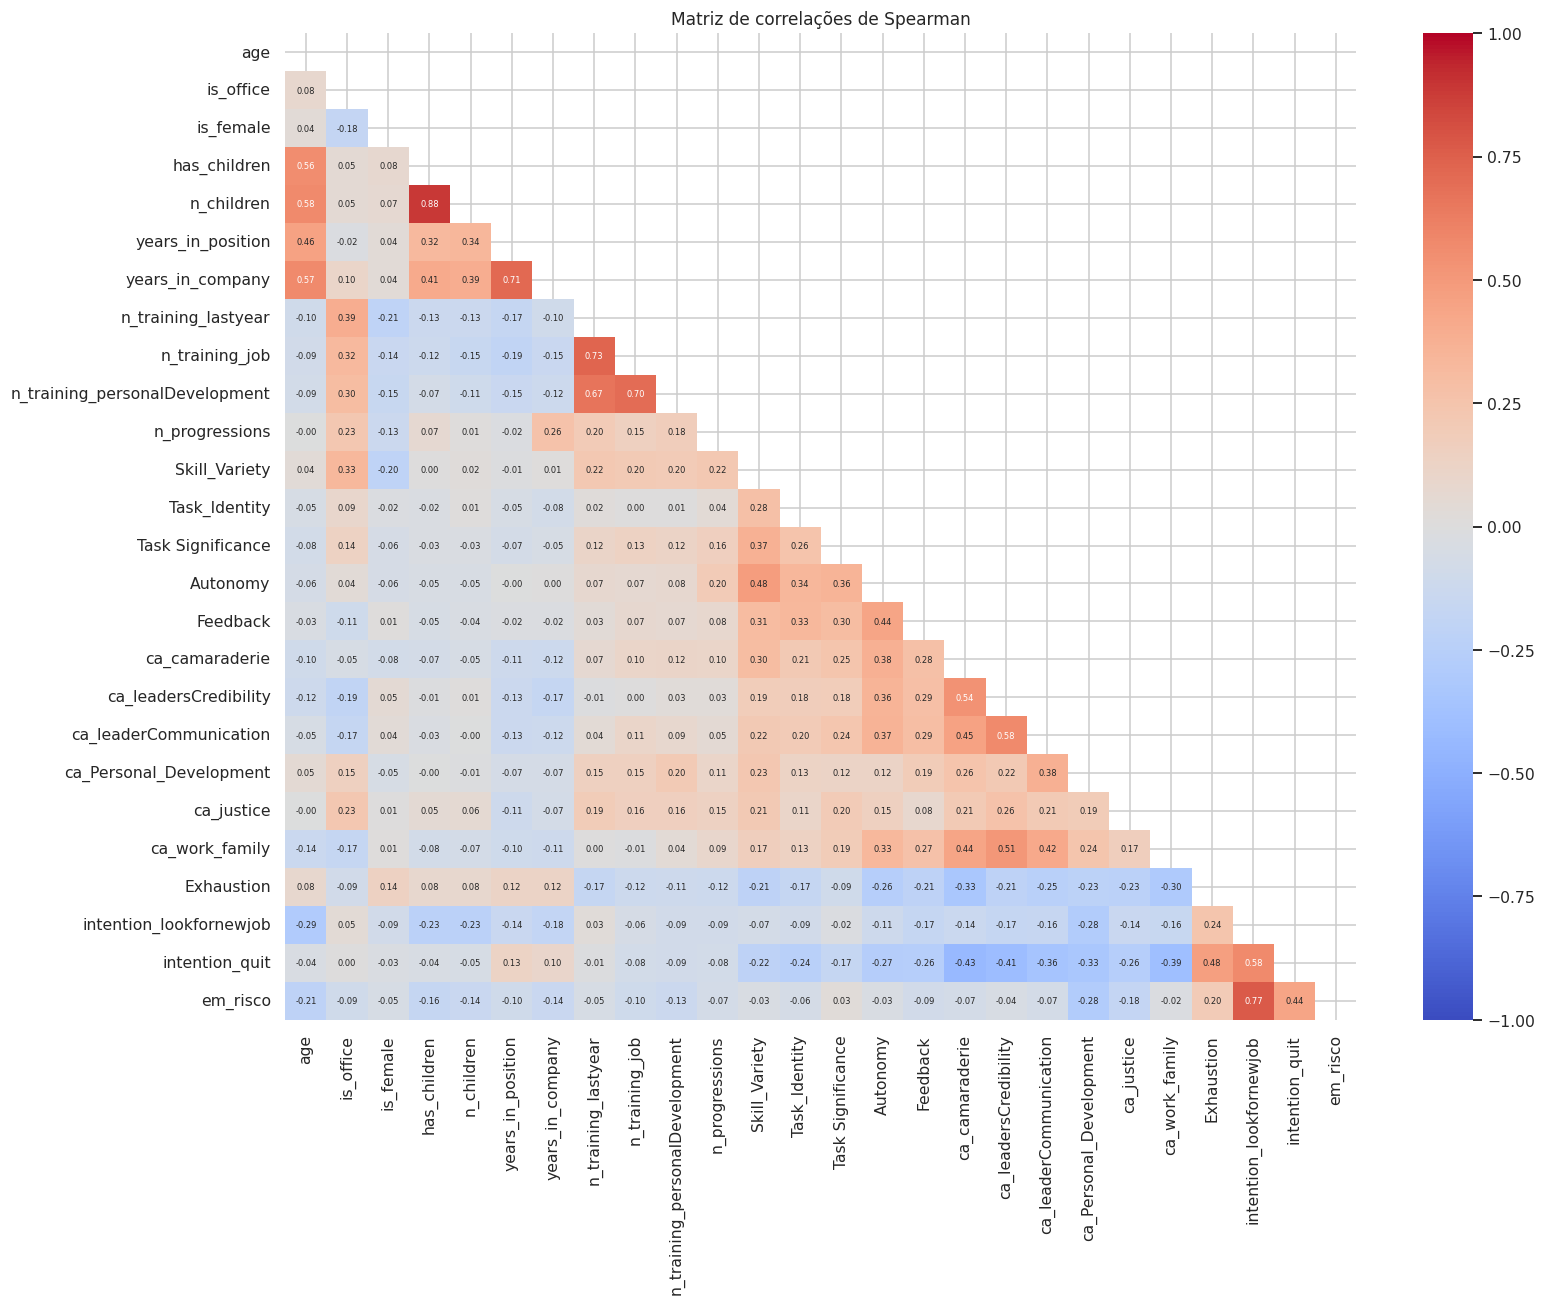

In [8]:
# 🟨 ALTERADO — revisto e documentado
from scipy import stats
from statsmodels.stats.proportion import proportion_confint
import statsmodels.api as sm

# Variáveis nominais e identificador excluídos da correlação numérica
excluir = ["indice", "marital status", "position_in_Company"]
cols = [c for c in df_clean.columns if c not in excluir]
corr = df_clean[cols].corr(method="spearman")

correlacao_target = (
    corr[target].drop([target, "em_risco", quit_col], errors="ignore")
    .sort_values()
    .to_frame("rho_Spearman")
)
display(correlacao_target.round(3))

mask = np.triu(np.ones_like(corr, dtype=bool))
fig, ax = plt.subplots(figsize=(15, 12))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", annot_kws={"size": 5.5},
            cmap="coolwarm", vmin=-1, vmax=1, center=0, ax=ax)
ax.set_title("Matriz de correlações de Spearman")
plt.tight_layout()
plt.show()


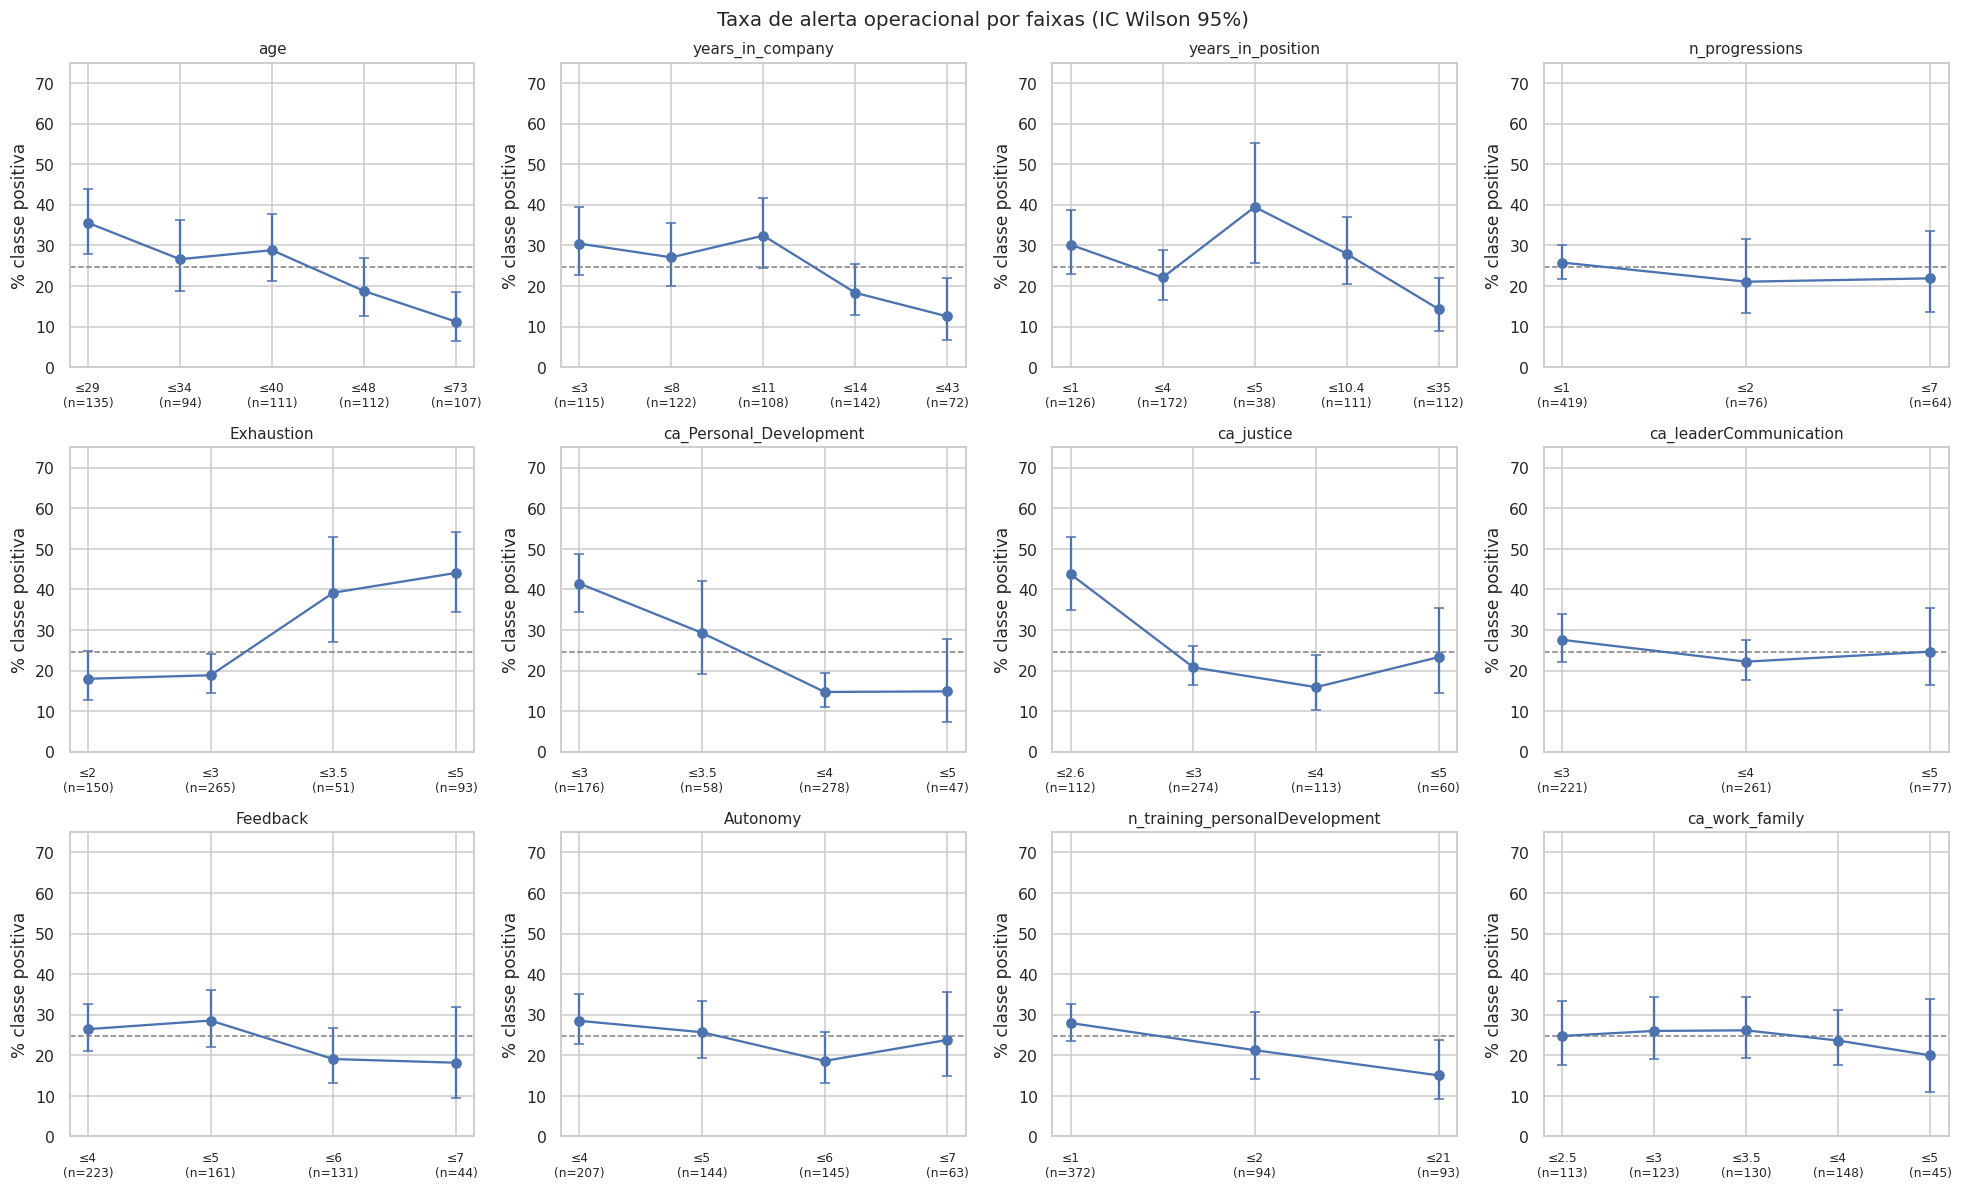

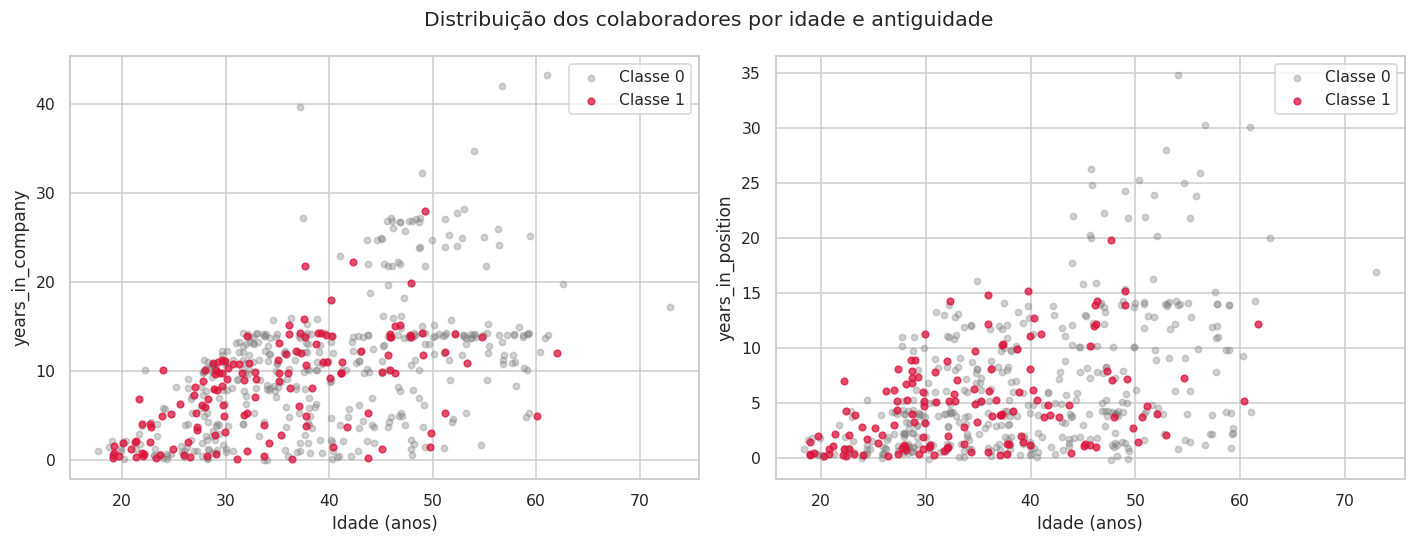

tenure_bin,0–2,2–5,5–10,10–20,20+
age_bin,,,,,
18–29,35.0,35.7,38.5,25.0,NaN
30–39,25.0,36.4,28.6,24.4,33.3
40–49,16.7,11.1,25.0,28.8,6.9
50+,33.3,37.5,0.0,8.8,0.0


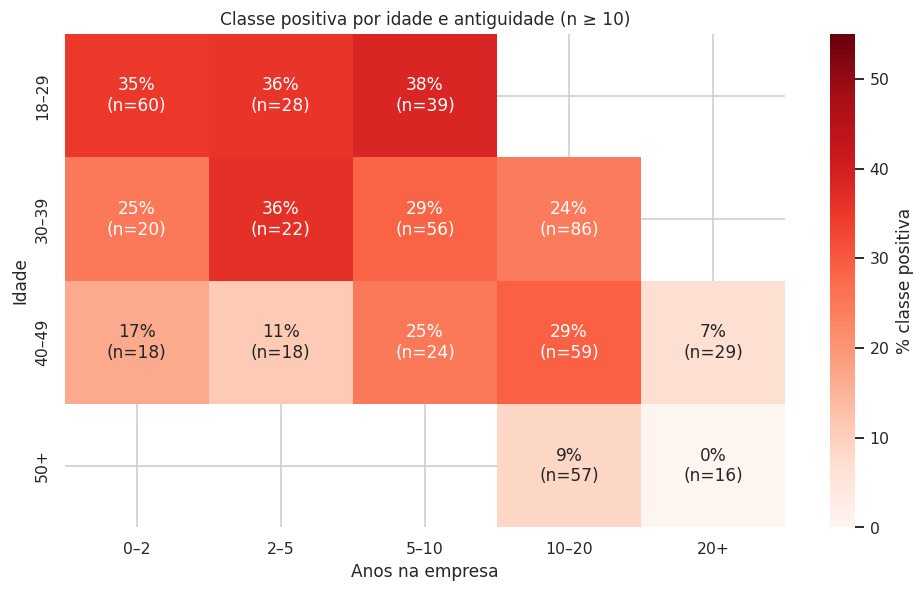

In [9]:
# 🟨 ALTERADO — revisto e documentado
# Taxa de classe positiva por faixas de variáveis selecionadas + IC Wilson de 95%
def risco_por_faixa(dados, variavel, q=5):
    faixas = pd.qcut(dados[variavel], q=q, duplicates="drop")
    tabela = dados.groupby(faixas, observed=True)["em_risco"].agg(["sum", "count"])
    tabela["taxa"] = tabela["sum"] / tabela["count"]
    tabela["lo"], tabela["hi"] = proportion_confint(
        tabela["sum"], tabela["count"], method="wilson")
    return tabela

variaveis = ["age", "years_in_company", "years_in_position", "n_progressions",
             "Exhaustion", "ca_Personal_Development", "ca_justice",
             "ca_leaderCommunication", "Feedback", "Autonomy",
             "n_training_personalDevelopment", "ca_work_family"]
taxa_global = df_clean["em_risco"].mean()

fig, axes = plt.subplots(3, 4, figsize=(18, 11))
for ax, var in zip(axes.flatten(), variaveis):
    g = risco_por_faixa(df_clean, var)
    x = np.arange(len(g))
    ax.errorbar(x, g["taxa"] * 100,
                yerr=[(g["taxa"]-g["lo"])*100, (g["hi"]-g["taxa"])*100],
                fmt="o-", capsize=3)
    ax.axhline(taxa_global * 100, color="gray", ls="--", lw=1)
    ax.set_xticks(x)
    ax.set_xticklabels([f"≤{iv.right:g}\n(n={n})" for iv, n in zip(g.index, g["count"])],
                       fontsize=8)
    ax.set_title(var, fontsize=10)
    ax.set_ylim(0, 75)
    ax.set_ylabel("% classe positiva")
fig.suptitle("Taxa de alerta operacional por faixas (IC Wilson 95%)", fontsize=13)
plt.tight_layout()
plt.show()

# 🟨 MANTIDO da análise original: dispersões de idade vs. antiguidade
rng = np.random.default_rng(42)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, coluna_anos in zip(axes, ["years_in_company", "years_in_position"]):
    idade_jitter = df_clean["age"] + rng.uniform(-0.4, 0.4, len(df_clean))
    anos_jitter = df_clean[coluna_anos] + rng.uniform(-0.3, 0.3, len(df_clean))
    negativos = df_clean["em_risco"].eq(0)
    ax.scatter(idade_jitter[negativos], anos_jitter[negativos],
               s=17, alpha=0.35, color="gray", label="Classe 0")
    ax.scatter(idade_jitter[~negativos], anos_jitter[~negativos],
               s=19, alpha=0.75, color="crimson", label="Classe 1")
    ax.set_xlabel("Idade (anos)")
    ax.set_ylabel(coluna_anos)
    ax.legend()
fig.suptitle("Distribuição dos colaboradores por idade e antiguidade")
plt.tight_layout()
plt.show()

# Tabela auditável do cruzamento de idade e antiguidade
df_clean["age_bin"] = pd.cut(df_clean["age"], [17, 29, 39, 49, 80],
                             labels=["18–29", "30–39", "40–49", "50+"])
df_clean["tenure_bin"] = pd.cut(df_clean["years_in_company"],
                                [-0.01, 2, 5, 10, 20, 50],
                                labels=["0–2", "2–5", "5–10", "10–20", "20+"])
taxa = df_clean.pivot_table(index="age_bin", columns="tenure_bin", values="em_risco",
                            aggfunc="mean", observed=True) * 100
cont = df_clean.pivot_table(index="age_bin", columns="tenure_bin", values="em_risco",
                            aggfunc="count", observed=True).fillna(0).astype(int)
display(taxa.round(1))
taxa_mostrar = taxa.where(cont >= 10)
anot = taxa_mostrar.round(0).astype("Int64").astype(str) + "%\n(n=" + cont.astype(str) + ")"
anot = anot.where(cont >= 10, "")
fig, ax = plt.subplots(figsize=(9, 5.5))
sns.heatmap(taxa_mostrar, annot=anot, fmt="", cmap="Reds", vmin=0, vmax=55,
            cbar_kws={"label": "% classe positiva"}, ax=ax)
ax.set_title("Classe positiva por idade e antiguidade (n ≥ 10)")
ax.set_xlabel("Anos na empresa")
ax.set_ylabel("Idade")
plt.tight_layout()
plt.show()


Pseudo-R² de McFadden: 0.181


,OR,IC95_inf,IC95_sup,p
ca_Personal_Development,0.552,0.431,0.707,0.000
is_female,0.659,0.415,1.045,0.076
age,0.681,0.500,0.929,0.015
ca_justice,0.726,0.574,0.918,0.007
years_in_company,0.754,0.553,1.028,0.074
has_children,0.771,0.456,1.303,0.332
n_training_personalDevelopment,0.808,0.605,1.079,0.148
Feedback,0.920,0.723,1.170,0.496
ca_leadersCredibility,1.051,0.758,1.457,0.764
ca_leaderCommunication,1.064,0.805,1.407,0.662


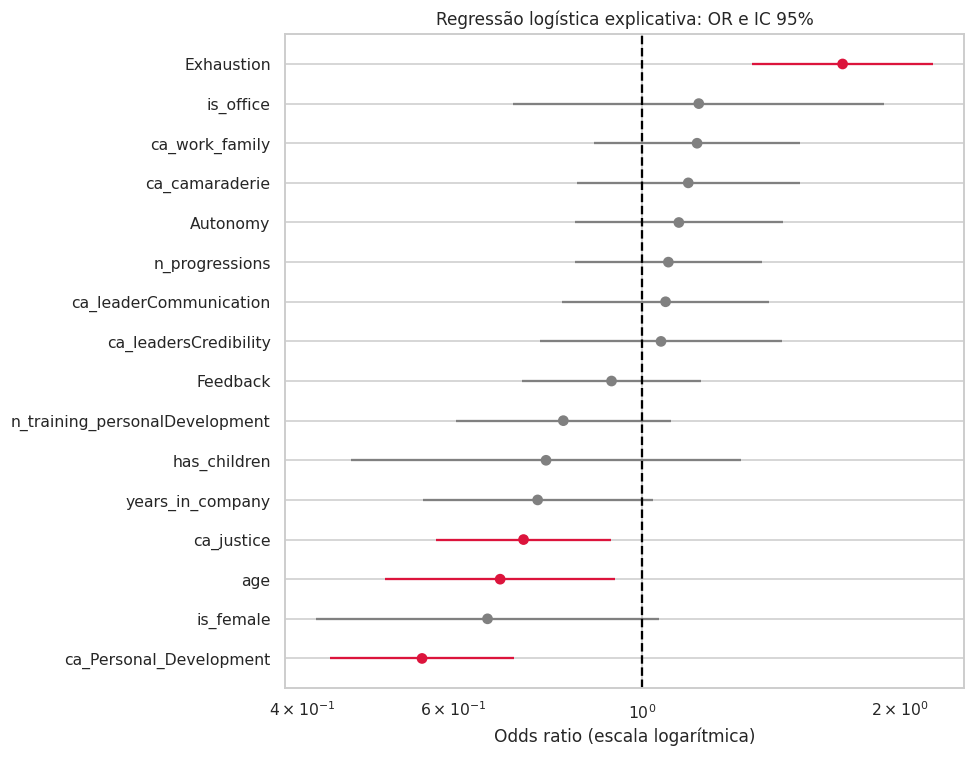

In [10]:
# 🟨 ALTERADO — revisto e documentado
# Regressão logística explicativa do ponto 3 (não substitui o ponto 4)
preditores = ["age", "years_in_company", "has_children", "is_female", "is_office",
              "Exhaustion", "ca_Personal_Development", "ca_leadersCredibility",
              "ca_leaderCommunication", "ca_camaraderie", "ca_justice",
              "ca_work_family", "Feedback", "Autonomy", "n_progressions",
              "n_training_personalDevelopment"]
binarias = ["has_children", "is_female", "is_office"]

X_explicativo = df_clean[preditores].copy()
for col in preditores:
    if col not in binarias:
        X_explicativo[col] = (
            (X_explicativo[col] - X_explicativo[col].mean()) / X_explicativo[col].std()
        )

modelo_explicativo = sm.Logit(
    df_clean["em_risco"], sm.add_constant(X_explicativo)
).fit(disp=0)

ors = pd.DataFrame({
    "OR": np.exp(modelo_explicativo.params),
    "IC95_inf": np.exp(modelo_explicativo.conf_int()[0]),
    "IC95_sup": np.exp(modelo_explicativo.conf_int()[1]),
    "p": modelo_explicativo.pvalues,
}).drop("const").sort_values("OR")
display(ors.round(3))
print("Pseudo-R² de McFadden:", round(modelo_explicativo.prsquared, 3))

fig, ax = plt.subplots(figsize=(9, 7))
yy = np.arange(len(ors))
cores = np.where(ors["p"] < 0.05, "crimson", "gray")
ax.hlines(yy, ors["IC95_inf"], ors["IC95_sup"], colors=cores)
ax.scatter(ors["OR"], yy, c=cores, zorder=3)
ax.axvline(1, color="black", ls="--")
ax.set_xscale("log")
ax.set_yticks(yy)
ax.set_yticklabels(ors.index)
ax.set_xlabel("Odds ratio (escala logarítmica)")
ax.set_title("Regressão logística explicativa: OR e IC 95%")
plt.tight_layout()
plt.show()


## **3.2 Teste de Hipóteses**

De modo a averiguar a validade das hipóteses anteriormente levantadas, mas também a encontrar novas relações entre os dados, foram analisadas diferentes métricas.

## **Conclusões dos Testes de Hipóteses**

Os testes foram realizados sobre o dataset limpo e imputado (n = 559), com o target `intention_lookfornewjob` (contínuo, 1-7) para as correlações de Spearman e a sua versão binária (≥ 4 = em risco) para os gráficos e a regressão logística. Os p-values não foram corrigidos para testes múltiplos, pelo que valores próximos de 0,05 devem ser lidos com cautela, e o tamanho do efeito (ρ) é o critério principal.

### **Veredictos**

| Hipótese | Variáveis | Esperado | Observado (ρ de Spearman) | Regressão logística (efeito independente) | Veredicto |
|---|---|---|---|---|---|
| **H1** Clima organizacional | 6 dimensões `ca_*` | (−) | −0,14 a −0,28; todas negativas | Só `Personal_Development` (OR 0,55) e `justice` (OR 0,73) mantêm efeito | **Confirmada**, mas só em parte independente |
| **H2** Características do trabalho | 5 variáveis Hackman & Oldham | (−) | `Feedback` −0,17, `Autonomy` −0,11; as restantes entre −0,09 e −0,02 | Nenhuma significativa | **Maioritariamente não confirmada** |
| **H3** Exaustão | `Exhaustion` | (+) | +0,25 | OR 1,72 por desvio-padrão | **Confirmada** |
| **H4** Desenvolvimento profissional | `ca_Personal_Development`, `n_progressions`, `years_in_position` | (−) | −0,28; −0,09; −0,14 | `Personal_Development` significativa; `n_progressions` não | **Parcialmente confirmada** (só o desenvolvimento pessoal percebido) |
| **H5** Antiguidade | `years_in_company`, `years_in_position` | Não linear | −0,18; −0,14 | Perde significância ao controlar a idade | **Parcialmente confirmada**: relação negativa, sem forma em U |
| **H6** Formação e progressão | 3 variáveis `n_training_*`, `n_progressions` | (−) | +0,03; −0,06; −0,09; −0,09 | Nenhuma significativa | **Não confirmada** |
| **H7** Sociodemográficos | `age`, `is_female` | Exploratória | −0,29; −0,09 | Idade significativa (OR 0,68); género não | **Idade: efeito robusto**; género: inconclusivo |

**Variáveis não hipotetizadas:** `has_children` (ρ = −0,23) e o estado civil (solteiros com maior risco) têm efeito isolado, mas desaparecem quando a idade é controlada, pelo que funcionam sobretudo como proxies da idade. `is_office` não mostra efeito (ρ = 0,05).

### **O que se confirmou, falhou e surpreendeu**

- **Confirmou-se:** a exaustão, a perceção de desenvolvimento pessoal e a idade são <mark>algumas das variáveis com associações mais evidentes nos dados</mark>. Foi também confirmada a direção esperada de todas as dimensões do clima, embora apenas duas mantenham efeito próprio.
- **Falhou:** as características do trabalho (exceto o *feedback*), a formação e as progressões, bem como a existência de uma forma em U na antiguidade. Os resultados indicam que o risco permanece em torno de 25-33% durante os primeiros ~10 anos na empresa e só diminui depois.
- **Surpreendeu:** a fraca relevância da formação e das progressões, e o facto de a idade explicar o efeito de variáveis como os filhos e o estado civil.

### **Limitações**

- Os efeitos são de pequena a moderada dimensão (|ρ| ≤ 0,30, pseudo-R² = 0,18), pelo que se espera um desempenho preditivo modesto.
- Trata-se de associações medidas no mesmo momento, entre intenções (e não saídas reais), e não de causas.
- O dataset junta três empresas sem identificador, pelo que efeitos específicos de cada empresa ficam diluídos.
- <mark>A imputação por mediana pode reduzir a variabilidade e alterar as estimativas de incerteza; não podemos garantir que a alteração dos p-values seja sempre numa direção concreta.</mark>
- As faixas dos gráficos e a lista de variáveis da regressão envolveram escolhas, e a ausência de significância não prova a ausência de efeito.
- Estas análises usaram o dataset completo; na modelação supervisionada, a imputação será refeita apenas com os dados de treino.

### **Implicações para as fases seguintes**

- Manter todas as variáveis hipotetizadas no modelo supervisionado, independentemente do resultado dos testes.
- Considerar a fusão das três variáveis de formação (muito correlacionadas entre si e com pouco efeito) e manter `ca_Personal_Development` e `ca_justice` separadas.
- Usar a idade com cuidado, tanto como *feature* como na análise de equidade (objetivo 10), dado ser o preditor mais forte.
- Analisar a sensibilidade das conclusões a outros limiares do target (3 e 5).

## **3.3 Engenharia de variáveis — cálculo e avaliação**

O alfa de Cronbach mede a consistência interna de um conjunto de itens. É utilizado como apoio para a construção do índice relacional, em conjunto com a coerência do conteúdo. Para variáveis de contagem de formação, um alfa elevado não garante que a soma seja uma contagem de eventos distintos.


In [11]:
# 🟨 ALTERADO — revisto e documentado
itens_relacional = [
    "ca_leadersCredibility", "ca_leaderCommunication",
    "ca_camaraderie", "ca_work_family"
]
itens_formacao = [
    "n_training_lastyear", "n_training_job", "n_training_personalDevelopment"
]

def cronbach_alpha(X):
    k = X.shape[1]
    return k / (k - 1) * (
        1 - X.var(ddof=1).sum() / X.sum(axis=1).var(ddof=1)
    )

print(f"Alfa de Cronbach — clima relacional: {cronbach_alpha(df_clean[itens_relacional]):.2f}")
print(f"Alfa de Cronbach — itens de formação: {cronbach_alpha(df_clean[itens_formacao]):.2f}")

df_clean["clima_relacional"] = df_clean[itens_relacional].mean(axis=1)

# 🟨 ALTERADO: nome rigoroso; é um índice, NÃO um n.º garantido de cursos únicos
df_clean["indice_formacao"] = df_clean[itens_formacao].sum(axis=1)

# 🟨 ALTERADO: mantemos n_children no df_clean, mas retiramo-la dos modelos
nao_features = ["indice", "intention_lookfornewjob", "intention_quit",
                "em_risco", "age_bin", "tenure_bin", "n_children"]
cat_features = ["marital status", "position_in_Company"]
indices = ["clima_relacional", "indice_formacao"]

features_A = [c for c in df_clean.columns
              if c not in nao_features + cat_features + indices]
features_B = [c for c in features_A
              if c not in itens_relacional + itens_formacao] + indices

print("Dimensão do DataFrame exploratório:", df_clean.shape)
print("Versão A:", len(features_A), "variáveis; Versão B:", len(features_B))
display(df_clean[["clima_relacional", "indice_formacao"]].describe().round(2).T)
display(pd.DataFrame({
    "Versão A — originais": pd.Series(features_A),
    "Versão B — com índices": pd.Series(features_B)
}))

assert len(features_A) == 22 and len(features_B) == 17
assert df_clean[["clima_relacional", "indice_formacao"]].notna().all().all()


Alfa de Cronbach — clima relacional: 0.80
Alfa de Cronbach — itens de formação: 0.86
Dimensão do DataFrame exploratório: (559, 33)
Versão A: 22 variáveis; Versão B: 17


,count,mean,std,min,25%,50%,75%,max
clima_relacional,559.0,3.32,0.79,1.12,2.88,3.5,3.88,5.0
indice_formacao,559.0,5.41,6.30,0.00,2.00,4.0,6.00,60.0


,Versão A — originais,Versão B — com índices
0,age,age
1,is_office,is_office
2,is_female,is_female
3,has_children,has_children
4,years_in_position,years_in_position
5,years_in_company,years_in_company
6,n_training_lastyear,n_progressions
7,n_training_job,Skill_Variety
8,n_training_personalDevelopment,Task_Identity
9,n_progressions,Task Significance


### **3.3.1 Fundamentação dos índices criados**

Com base na análise de correlações e nos testes de hipóteses, avaliou-se a criação de features que agrupem variáveis redundantes. O objetivo é reduzir a colinearidade e o número de variáveis, mantendo a interpretabilidade. Os critérios foram a correlação entre os itens, a consistência interna (expressa através do alfa de Cronbach ≥ 0,7) e a coerência conceptual.

### **Variáveis criadas**

| Variável | Variáveis agrupadas | Método | Justificação |
|---|---|---|---|
| `clima_relacional` | `ca_leadersCredibility`, `ca_leaderCommunication`, `ca_camaraderie`, `ca_work_family` | Média | Alfa = 0,80; correlações entre os itens de 0,42 a 0,58; representa a perceção do ambiente relacional e de apoio no trabalho. A correlação do índice com o target (ρ = −0,21) é superior à de cada item isolado |
| <mark>`indice_formacao`</mark> | `n_training_lastyear`, `n_training_job`, `n_training_personalDevelopment` | Soma | Alfa = 0,86; correlações entre os itens de 0,67 a 0,73; <mark>é um índice de intensidade formativa; a soma pode contar a mesma formação mais do que uma vez, pois as variáveis podem sobrepor-se</mark> |

As novas variáveis são calculados após a imputação e <mark>não utilizam diretamente o *target*. No entanto, a sua construção para previsão deve ocorrer após a imputação ajustada apenas no treino, dentro do Pipeline do ponto 4.</mark> A <mark>`indice_formacao`</mark> apresenta uma distribuição fortemente assimétrica (assimetria de 2,9), pelo que será aplicada uma transformação logarítmica no modelo de regressão logística.

### **Variáveis mantidas separadas**

- **`ca_Personal_Development` e `ca_justice`:** apresentam correlações mais baixas com as restantes dimensões do clima (0,17 a 0,38) e mantêm um efeito independente na regressão logística, pelo que agrupá-las com as restantes diluiria o seu sinal.
- **Características do trabalho:** a consistência interna é fraca (alfa = 0,69) e a média diluiria o sinal do `Feedback`, a dimensão com maior associação ao target.
- **Idade, antiguidade na empresa e `has_children`:** estão correlacionadas, mas medem conceitos distintos e a correlação é inferior a 0,7.

Foi ainda testada a taxa de progressões por ano de empresa, sem associação relevante ao target (ρ = −0,08), pelo que foi descartada.

### **Variável removida**

A variável `n_children` foi eliminada do dataset por ser redundante com `has_children` (ρ = 0,88): ambas têm a mesma relação com o target (ρ = −0,23), 94% dos colaboradores com filhos têm 1 ou 2 filhos (pelo que o número exato acrescenta pouca informação) e a variável tinha valores em falta. A correlação entre `years_in_company` e `years_in_position` (0,71) encontra-se no limite do critério definido (≥ 0,7), e a sua redundância será reavaliada na fase de modelação, através do fator de inflação da variância (VIF).

### **Substituição ou coexistência**

As variáveis originais que compõem os índices mantêm-se no dataset, para preservar a rastreabilidade e permitir a análise detalhada no dashboard, mas **não são usadas em simultâneo com o respetivo índice** no mesmo modelo: o índice é uma combinação linear dos itens, pelo que incluir ambos introduziria colinearidade perfeita. Serão comparadas duas versões do modelo: **A** (variáveis originais) e **B** (índices em vez dos itens que os compõem).

<mark>🟨 **ALTERADO:** preservamos `n_children` no DataFrame para manter rastreabilidade; a variável é excluída apenas das listas de preditores. O índice de formação não é uma contagem comprovada de cursos únicos. As versões A e B serão recalculadas sem fuga de informação no ponto 4.</mark>

# **4. Supervised Model — Classificação do sinal de risco**

<mark>🟨 **PONTO 4 NOVO:** O objetivo obrigatório exige treinar pelo menos um algoritmo supervisionado, dividir treino e teste e escolher métricas adequadas. Esta secção segue os slides `Splitting_the_Data`, `Evaluating_Classifiers_KNN_Nayve_DecisionTree`, `Choose_Explain_Models` e `Tuning_in_Machine_Learning`.</mark>

**Questão preditiva:** usando respostas aos itens do questionário e informações administrativas, conseguimos prever a classe `intention_lookfornewjob ≥ 4` em colaboradores não utilizados durante o treino?

**Distinção crucial:** o resultado é uma classificação de intenção declarada, **não** uma estimativa validada da probabilidade de demissão efetiva. O valor 4 é tratado como sinal preventivo de atenção, e não como certeza de saída.

**Plano:** (i) separar antes da imputação; (ii) comparar *baseline*, regressões logísticas e uma floresta de referência; (iii) selecionar na validação cruzada do treino; (iv) avaliar o escolhido uma única vez no teste; (v) explicar os resultados e as limitações.

## **4.1 Divisão treino/teste e definição das variáveis**

Opta-se por uma divisão estratificada 70%/30%, com semente fixa para reprodutibilidade. A classe positiva representa aproximadamente 25% dos casos, pelo que a estratificação evita distribuições muito diferentes entre os subconjuntos. Não existe identificador de empresa nem data temporal; não é possível fazer uma divisão por empresa nem avaliar validação futura a partir destes dados.


In [12]:
# 🟨 NOVO — revisto e documentado
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate

# Reutilizar correções determinísticas, SEM a imputação global do ponto 2
X = df_sem_imputacao[features_A].copy()
y = df_sem_imputacao[target].ge(LIMIAR).astype(int)

# Exclusão expressa de variáveis que representam a resposta ou a identificam
assert target not in X.columns
assert "intention_quit" not in X.columns
assert "indice" not in X.columns
assert not (set(features_A) & {"em_risco", "age_bin", "tenure_bin"})

X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=42
)

resumo_split = pd.DataFrame({
    "Conjunto": ["Total", "Treino", "Teste"],
    "Observações": [len(y), len(y_treino), len(y_teste)],
    "Classe 0": [int((y==0).sum()), int((y_treino==0).sum()),
                 int((y_teste==0).sum())],
    "Classe 1": [int((y==1).sum()), int((y_treino==1).sum()),
                 int((y_teste==1).sum())],
    "% Classe 1": [100*y.mean(), 100*y_treino.mean(), 100*y_teste.mean()]
})
display(resumo_split.round(2))


,Conjunto,Observações,Classe 0,Classe 1,% Classe 1
0,Total,559,421,138,24.69
1,Treino,391,294,97,24.81
2,Teste,168,127,41,24.40


## **4.2 Pré-processamento dentro de um Pipeline**

<mark>🟨 **NOVO E ESSENCIAL — Prevenção de data leakage:** não utilizamos o `df_clean` imputado no ponto 2 para esta avaliação. O `SimpleImputer` ajusta as medianas **apenas nos dados de treino de cada fold**, aplicando-as depois às observações de validação ou teste. A normalização segue a mesma regra.</mark>

As duas variáveis de antiguidade merecem tratamento conjunto: a simples imputação por medianas independentes pode criar `years_in_position > years_in_company`. Para preservar a regra lógica do ponto 2, construímos um transformador que aprende as medianas de antiguidade só no treino e impede violações da restrição.

**Porquê regressão logística?** O problema é binário, temos 559 observações, e os coeficientes permitem uma explicação mais direta ao departamento de RH. Testaremos modelos com e sem ponderação de classes para observar a troca entre *recall* e *precision*. A versão B procura verificar se índices compostos retêm informação suficiente. Uma floresta limitada serve de comparação não linear, sem assumir automaticamente que maior complexidade significa maior qualidade.


In [13]:
# 🟨 NOVO — revisto e documentado
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier


class CorrigirAntiguidade(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None):
        self.med_emp_ = X["years_in_company"].median()
        self.med_pos_ = X["years_in_position"].median()
        return self

    def transform(self, X):
        X = X.copy()
        X["years_in_company"] = X["years_in_company"].fillna(
            np.maximum(self.med_emp_, X["years_in_position"].fillna(0)))
        X["years_in_position"] = X["years_in_position"].fillna(
            np.minimum(self.med_pos_, X["years_in_company"]))
        X["years_in_position"] = np.minimum(
            X["years_in_position"], X["years_in_company"])
        return X


def transformar_indices(X):
    # Executado DEPOIS da imputação ajustada no treino
    X = X.copy()
    X["clima_relacional"] = X[itens_relacional].mean(axis=1)
    X["indice_formacao"] = np.log1p(X[itens_formacao].sum(axis=1))
    return X.drop(columns=itens_relacional + itens_formacao)


def pipeline_logistica(pesos=None, usar_indices=False):
    etapas = [
        ("antiguidade", CorrigirAntiguidade()),
        ("imputacao", SimpleImputer(strategy="median").set_output(transform="pandas")),
    ]
    if usar_indices:
        etapas.append(("indices", FunctionTransformer(transformar_indices, validate=False)))
    etapas.extend([
        ("escala", StandardScaler()),
        ("classificador", LogisticRegression(
            max_iter=2000, class_weight=pesos, random_state=42))
    ])
    return Pipeline(etapas)


modelos = {
    "Baseline (classe maioritária)": DummyClassifier(strategy="most_frequent"),
    "Logística A | sem pesos": pipeline_logistica(),
    "Logística A | ponderada": pipeline_logistica(pesos="balanced"),
    "Logística B | ponderada": pipeline_logistica(pesos="balanced", usar_indices=True),
    "Random Forest A": Pipeline([
        ("antiguidade", CorrigirAntiguidade()),
        ("imputacao", SimpleImputer(strategy="median")),
        ("classificador", RandomForestClassifier(
            n_estimators=300, max_depth=5, min_samples_leaf=5,
            class_weight="balanced", random_state=42))
    ]),
}

print("Modelos preparados:", list(modelos))


Modelos preparados: ['Baseline (classe maioritária)', 'Logística A | sem pesos', 'Logística A | ponderada', 'Logística B | ponderada', 'Random Forest A']


## **4.3 Validação cruzada estratificada — escolha sem consultar o teste**

O conjunto de treino contém 391 observações. Para reduzir a dependência de uma só divisão, utilizamos cinco folds estratificados e reportamos **média ± desvio-padrão** das métricas. O teste com 168 pessoas permanece reservado. O algoritmo selecionado será decidido por desempenho na validação, legibilidade e custo conceptual dos erros.

**Métrica prioritária: recall da classe positiva.** Um falso negativo significa não sinalizar uma resposta classificada como alerta. Como sinalizar demasiados colaboradores também tem custos e possíveis efeitos sociais, a *precision* e o F1 continuam relevantes. A ROC-AUC avalia ordenação discriminativa e a Average Precision resume a curva precision–recall; nenhuma métrica isolada determina automaticamente a melhor intervenção.

<mark>🟨 **NOVO:** `class_weight="balanced"` altera a importância das classes durante o treino; não garante probabilidades calibradas nem elimina o custo dos falsos positivos. É comparado explicitamente com o modelo sem ponderação.</mark>


In [14]:
# 🟨 NOVO — revisto e documentado
from sklearn.metrics import make_scorer, precision_score

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
metricas_cv = {
    "recall": "recall",
    "precision": make_scorer(precision_score, zero_division=0),
    "f1": "f1",
    "roc_auc": "roc_auc",
    "average_precision": "average_precision",
    "balanced_accuracy": "balanced_accuracy",
}

linhas_cv = []
for nome, estimador in modelos.items():
    resultados = cross_validate(
        estimador, X_treino, y_treino, cv=cv,
        scoring=metricas_cv, error_score="raise"
    )
    linha = {"Modelo": nome}
    for metrica in metricas_cv:
        pontuacoes = resultados[f"test_{metrica}"]
        linha[f"{metrica} — média"] = pontuacoes.mean()
        linha[f"{metrica} — DP"] = pontuacoes.std()
    linhas_cv.append(linha)

resultados_cv = pd.DataFrame(linhas_cv)
display(resultados_cv.round(3))

# Comparação simplificada para apresentação
colunas_resumo = ["Modelo", "recall — média", "precision — média",
                  "f1 — média", "roc_auc — média", "average_precision — média"]
display(resultados_cv[colunas_resumo].sort_values("recall — média", ascending=False).round(3))


,Modelo,recall — média,recall — DP,precision — média,precision — DP,f1 — média,f1 — DP,roc_auc — média,roc_auc — DP,average_precision — média,average_precision — DP,balanced_accuracy — média,balanced_accuracy — DP
0,Baseline (classe maioritária),0.000,0.000,0.000,0.000,0.000,0.000,0.500,0.000,0.248,0.006,0.500,0.000
1,Logística A | sem pesos,0.351,0.105,0.585,0.136,0.423,0.093,0.743,0.058,0.558,0.113,0.629,0.048
2,Logística A | ponderada,0.639,0.101,0.451,0.081,0.523,0.074,0.747,0.058,0.564,0.115,0.685,0.061
3,Logística B | ponderada,0.638,0.107,0.435,0.073,0.511,0.069,0.744,0.061,0.568,0.115,0.676,0.057
4,Random Forest A,0.496,0.083,0.537,0.125,0.506,0.073,0.751,0.047,0.599,0.109,0.670,0.051


,Modelo,recall — média,precision — média,f1 — média,roc_auc — média,average_precision — média
2,Logística A | ponderada,0.639,0.451,0.523,0.747,0.564
3,Logística B | ponderada,0.638,0.435,0.511,0.744,0.568
4,Random Forest A,0.496,0.537,0.506,0.751,0.599
1,Logística A | sem pesos,0.351,0.585,0.423,0.743,0.558
0,Baseline (classe maioritária),0.000,0.000,0.000,0.500,0.248


### **4.3.1 Decisão fundamentada antes de usar o teste**

Selecionamos como modelo principal a **regressão logística ponderada, versão A**: privilegiamos a identificação da classe positiva, preservamos as variáveis originais mais facilmente interpretáveis e evitamos depender do índice composto de formação, cuja soma pode conter sobreposições. A versão B e o Random Forest são referências válidas, mas pequenas diferenças entre médias de folds não provam superioridade estatística.

O *baseline* identifica a dimensão da armadilha da *accuracy*: prever sempre a classe 0 acerta na maioria dos casos, mas obtém **recall = 0** para a classe positiva.

<mark>🟨 **DECISÃO DOCUMENTADA ANTES DO TESTE:** não mudar o modelo por causa dos resultados observados no conjunto de teste. Ajustes posteriores de hiperparâmetros e limiares têm de voltar à validação do treino.</mark>


## **4.4 Avaliação final no conjunto de teste**

Treinamos a configuração selecionada nas 391 observações do treino e avaliamos as previsões nas 168 restantes. O teste representa uma aproximação a dados não vistos dentro deste conjunto agregado; não demonstra generalização entre empresas, anos ou alterações do mercado de trabalho.

**Interpretação da matriz de confusão:** TP é um colaborador da classe positiva corretamente identificado; FN pertence à classe positiva, mas o modelo não o assinalou; FP foi assinalado sem pertencer à classe positiva; TN pertence à classe negativa e foi corretamente identificado.

**Cálculos:** `Recall = TP/(TP+FN)`, `Precision = TP/(TP+FP)`, `F1 = 2·Precision·Recall/(Precision+Recall)` e `Accuracy = (TP+TN)/N`. A *balanced accuracy* calcula a média do recall das duas classes.


,Métrica,Teste
0,Accuracy,0.655
1,Balanced accuracy,0.648
2,Precision,0.377
3,Recall,0.634
4,F1-score,0.473
5,ROC-AUC,0.705
6,Average precision,0.512


,Tipo,N.º de colaboradores
0,TN — negativos corretamente identificados,84
1,FP — falsos alarmes,43
2,FN — positivos não detetados,15
3,TP — positivos corretamente identificados,26


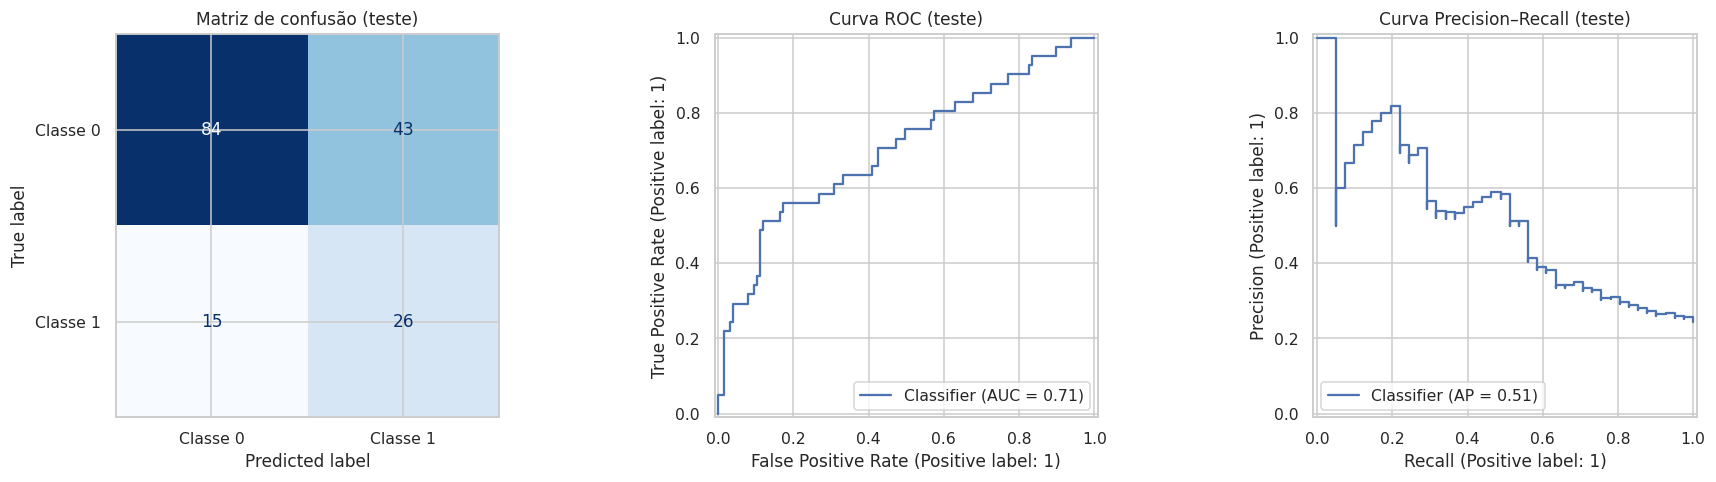

,Modelo,Accuracy,Recall,Precision
0,Baseline,0.756,0.000,0.000
1,Logística A | ponderada,0.655,0.634,0.377


In [15]:
# 🟨 NOVO — revisto e documentado
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, average_precision_score, confusion_matrix,
    ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay
)

nome_final = "Logística A | ponderada"
modelo_final = modelos[nome_final]
modelo_final.fit(X_treino, y_treino)
y_prev = modelo_final.predict(X_teste)
y_score = modelo_final.predict_proba(X_teste)[:, 1]

metricas_finais = pd.DataFrame({
    "Métrica": ["Accuracy", "Balanced accuracy", "Precision", "Recall",
                "F1-score", "ROC-AUC", "Average precision"],
    "Teste": [accuracy_score(y_teste, y_prev),
              balanced_accuracy_score(y_teste, y_prev),
              precision_score(y_teste, y_prev, zero_division=0),
              recall_score(y_teste, y_prev),
              f1_score(y_teste, y_prev),
              roc_auc_score(y_teste, y_score),
              average_precision_score(y_teste, y_score)]
})
display(metricas_finais.round(3))

tn, fp, fn, tp = confusion_matrix(y_teste, y_prev).ravel()
contagens_confusao = pd.DataFrame({
    "Tipo": ["TN — negativos corretamente identificados",
             "FP — falsos alarmes", "FN — positivos não detetados",
             "TP — positivos corretamente identificados"],
    "N.º de colaboradores": [tn, fp, fn, tp]
})
display(contagens_confusao)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
ConfusionMatrixDisplay.from_predictions(
    y_teste, y_prev, display_labels=["Classe 0", "Classe 1"],
    cmap="Blues", colorbar=False, ax=axes[0])
axes[0].set_title("Matriz de confusão (teste)")
RocCurveDisplay.from_predictions(y_teste, y_score, ax=axes[1])
axes[1].set_title("Curva ROC (teste)")
PrecisionRecallDisplay.from_predictions(y_teste, y_score, ax=axes[2])
axes[2].set_title("Curva Precision–Recall (teste)")
plt.tight_layout()
plt.show()

# Comparação explicativa: classificador que prevê sempre sem risco
baseline_final = DummyClassifier(strategy="most_frequent")
baseline_final.fit(X_treino, y_treino)
prev_base = baseline_final.predict(X_teste)
comparacao_final = pd.DataFrame({
    "Modelo": ["Baseline", nome_final],
    "Accuracy": [accuracy_score(y_teste, prev_base), accuracy_score(y_teste, y_prev)],
    "Recall": [recall_score(y_teste, prev_base), recall_score(y_teste, y_prev)],
    "Precision": [precision_score(y_teste, prev_base, zero_division=0),
                  precision_score(y_teste, y_prev, zero_division=0)],
})
display(comparacao_final.round(3))


### **4.4.1 Interpretação dos resultados**

No conjunto de teste, a regressão logística ponderada identifica **26 dos 41 colaboradores da classe positiva**, deixando 15 por identificar (*recall* ≈ **63,4%**). Dos **69 colaboradores sinalizados**, 26 pertencem de facto à classe positiva (*precision* ≈ **37,7%**). Verificam-se 43 falsos positivos e 84 verdadeiros negativos.

A *accuracy* ≈ **65,5%** é inferior à do *baseline* (≈ **75,6%**), mas o *baseline* não deteta **nenhum** positivo. Isso demonstra por que motivo escolher só pela *accuracy* seria inadequado. A ROC-AUC ≈ **0,705** indica uma discriminação moderada dentro desta amostra. Os resultados não autorizam afirmar que o modelo prevê a saída efetiva de um trabalhador.

**Implicação de gestão:** sinalizar falsos positivos pode ser aceitável para ações gerais, leves, transparentes e voluntárias de apoio, mas não para decisões automáticas individuais, vigilância ou sanções. Não conhecemos os custos reais de cada tipo de erro, nem o limite de capacidade de intervenção dos RH; portanto, não é possível afirmar que este limiar é economicamente ótimo.

<mark>🟨 **NOVO — Cautela preditiva:** o `predict_proba` de uma regressão logística com pesos não deve ser apresentado diretamente como probabilidade calibrada de demissão. Para o dashboard, é mais seguro comunicar a categoria operacional e a incerteza, ou calibrar e validar as pontuações num trabalho adicional.</mark>


## **4.5 Interpretação dos coeficientes e relações com as hipóteses**

Como a regressão logística é um modelo transparente, podemos visualizar os sinais dos seus coeficientes. Como foi aplicado `StandardScaler`, os coeficientes refletem alterações de uma unidade de desvio-padrão na variável padronizada (incluindo binárias). Coeficientes positivos elevam as *log-odds* da classe positiva **condicionadas às outras variáveis incluídas**; negativos reduzem-nas.

**Limitações:** coeficientes correlacionados são sensíveis à inclusão de outras variáveis; regularização e ponderação de classes afetam os valores; a análise é preditiva e não causal. Por isso, esta visualização complementa, mas não substitui, os testes exploratórios do ponto 3.


Violações de antiguidade após transformação do teste: 0


,Variável,Coeficiente padronizado,Odds ratio por +1 DP
18,ca_Personal_Development,-0.827,0.437
0,age,-0.484,0.616
8,n_training_personalDevelopment,-0.459,0.632
5,years_in_company,-0.290,0.748
2,is_female,-0.275,0.760
19,ca_justice,-0.269,0.764
7,n_training_job,-0.231,0.794
14,Feedback,-0.228,0.796
1,is_office,-0.152,0.859
15,ca_camaraderie,-0.054,0.947


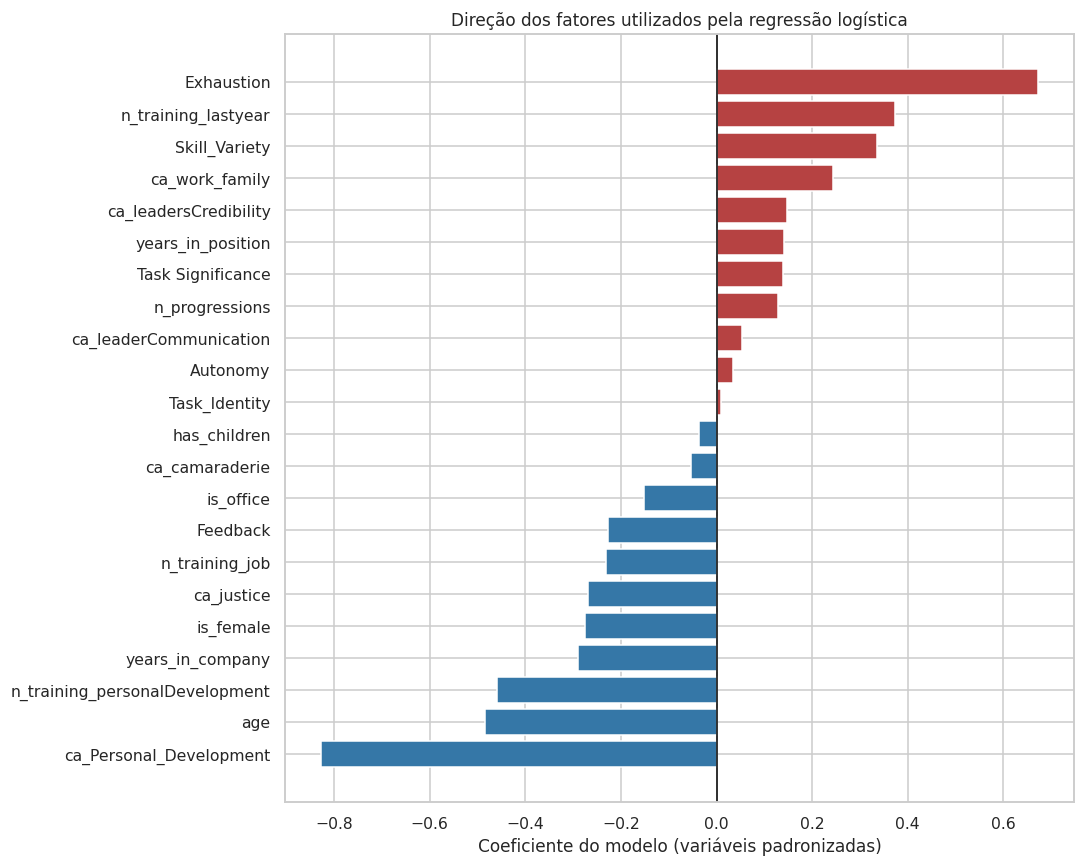

In [16]:
# 🟨 NOVO — revisto e documentado
coeficientes = pd.DataFrame({
    "Variável": features_A,
    "Coeficiente padronizado": modelo_final.named_steps["classificador"].coef_[0]
}).sort_values("Coeficiente padronizado")
coeficientes["Odds ratio por +1 DP"] = np.exp(
    coeficientes["Coeficiente padronizado"])
display(coeficientes.round(3))

fig, ax = plt.subplots(figsize=(10, 8))
cores = np.where(coeficientes["Coeficiente padronizado"] > 0,
                 "#b64242", "#3577a7")
ax.barh(coeficientes["Variável"], coeficientes["Coeficiente padronizado"],
        color=cores)
ax.axvline(0, color="black", lw=1)
ax.set_xlabel("Coeficiente do modelo (variáveis padronizadas)")
ax.set_title("Direção dos fatores utilizados pela regressão logística")
plt.tight_layout()
plt.show()

# Verificação do tratamento especial de antiguidade no conjunto de teste
teste_apos_regras = modelo_final.named_steps["antiguidade"].transform(X_teste)
violacoes_teste = int((teste_apos_regras["years_in_position"] >
                      teste_apos_regras["years_in_company"]).sum())
print("Violações de antiguidade após transformação do teste:", violacoes_teste)
assert violacoes_teste == 0


## **4.6 Conclusões, limitações e ligação aos próximos objetivos**

**Resposta à questão preditiva:** há sinal preditivo nas variáveis do inquérito e administrativas. O modelo identificado por validação cruzada apresenta discriminação acima do classificador trivial e permite identificar parte dos colaboradores com intenção declarada mais elevada de procurar emprego. Porém, a taxa de falsos positivos é relevante e o conjunto de teste inclui apenas 41 observações positivas. O desempenho deverá ser visto como um resultado exploratório e não como uma ferramenta validada de decisão individual.

**Limitações essenciais:**

1. O `target` é uma intenção ordinal transformada numa variável binária; não há observação da saída real.
2. As respostas são transversais; correlação ou coeficiente preditivo não demonstram causa.
3. Os dados vêm de três empresas sem identificador; não se pode medir generalização empresa a empresa.
4. Os intervalos de confiança da validação podem ser amplos com 559 linhas e uma classe positiva minoritária.
5. A escolha de variáveis foi apoiada por uma análise exploratória da amostra completa; portanto, o conjunto de teste não é totalmente independente de todas as decisões de investigação anteriores. É necessária validação externa para alegações fortes de generalização.
6. As características sensíveis `age` e `is_female` exigem uma análise de equidade no objetivo opcional 10. Excluí-las não elimina necessariamente enviesamentos, porque outras variáveis podem funcionar como proxies.

**Objetivo 7 — opcional:** a comparação inicial entre dois algoritmos e versões de variáveis já foi preparada, mas **ainda falta a otimização formal de hiperparâmetros**, com validação e documentação da seleção final, para o objetivo opcional ficar completo. Não devem escolher parâmetros por resultados do teste.

**Objetivo 8 — opcional:** a ponderação de classes trata parcialmente o desequilíbrio. Para uma avaliação mais rigorosa, estudar os limiares do *target* (≥ 3, ≥ 4, ≥ 5) e os limiares de decisão do classificador, sempre com validação interna, e considerar a natureza ordinal original.

**Objetivos 5 e 6 — ainda por executar:** análise não supervisionada e dashboard interativo com janelas de *who*, *why* e *what to do*. Os objetivos 9 e 10 acrescentam nudges e uma avaliação ética.

<mark>🟨 **CHECKLIST DO PONTO 4:** algoritmo supervisionado treinado ✓; divisão treino/teste ✓; métricas adequadas ✓; baseline ✓; validação cruzada ✓; comparação de modelos ✓; explicabilidade ✓; justificação de escolhas ✓; limitações e prevenção de fuga de informação ✓.</mark>

**Entrega prevista no enunciado:** apresentação para o conselho (~10 minutos), dashboard interativo e ZIP contendo notebook/código executável, dataset tratado, eventuais modelos e README. Um relatório Word autónomo não surge como entrega obrigatória.
